In [1]:
# Cell 1.1: Thiết lập môi trường, seed và cấu trúc thư mục
import os
import sys
import json
import random
import numpy as np
import pandas as pd
import sklearn
import torch

# 1. Cố định Random Seed trên toàn hệ thống
SEED = 42

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)

# 2. Khởi tạo cấu trúc thư mục lưu trữ artifacts
OUTPUT_DIRS = [
    "outputs/models",
    "outputs/figures",
    "outputs/metrics"
]
for d in OUTPUT_DIRS:
    os.makedirs(d, exist_ok=True)

# 3. Ghi nhận phiên bản môi trường thực thi
print("=== THÔNG TIN MÔI TRƯỜNG THỰC THI ===")
print(f"Python version      : {sys.version.split()[0]}")
print(f"PyTorch version     : {torch.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")
print(f"Pandas version      : {pd.__version__}")
print(f"NumPy version       : {np.__version__}")
print(f"CUDA Available      : {torch.cuda.is_available()}")
print("Trạng thái: Đã cố định SEED = 42 và tạo thành công cây thư mục outputs/.")

=== THÔNG TIN MÔI TRƯỜNG THỰC THI ===
Python version      : 3.11.16
PyTorch version     : 2.14.0+cpu
Scikit-learn version: 1.9.0
Pandas version      : 3.0.5
NumPy version       : 2.4.6
CUDA Available      : False
Trạng thái: Đã cố định SEED = 42 và tạo thành công cây thư mục outputs/.


In [2]:
# Cell 1.2: Nạp dữ liệu và kiểm tra cấu trúc ban đầu
DATA_PATH = "diabetes_dataset.csv"
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Không tìm thấy file {DATA_PATH}. Vui lòng kiểm tra lại đường dẫn!")

df_raw = pd.read_csv(DATA_PATH)

print("=== CẤU TRÚC TẬP DỮ LIỆU GỐC ===")
print(f"Số dòng (Observations) : {df_raw.shape[0]:,}")
print(f"Số cột (Attributes)    : {df_raw.shape[1]}")
print("\nDanh sách cột và kiểu dữ liệu:")
print(df_raw.dtypes)

print("\nNăm bản ghi đầu tiên:")
display(df_raw.head())

=== CẤU TRÚC TẬP DỮ LIỆU GỐC ===
Số dòng (Observations) : 100,000
Số cột (Attributes)    : 16

Danh sách cột và kiểu dữ liệu:
year                      int64
gender                      str
age                     float64
location                    str
race:AfricanAmerican      int64
race:Asian                int64
race:Caucasian            int64
race:Hispanic             int64
race:Other                int64
hypertension              int64
heart_disease             int64
smoking_history             str
bmi                     float64
hbA1c_level             float64
blood_glucose_level       int64
diabetes                  int64
dtype: object

Năm bản ghi đầu tiên:


,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0


In [3]:
# Cell 1.3: Kiểm tra chất lượng dữ liệu (thiếu, trùng lặp, ngoại lai)
print("=== 1. KIỂM TRA GIÁ TRỊ KHUYẾT THIẾU (MISSING VALUES) ===")
missing_series = df_raw.isnull().sum()
print(missing_series)

print("\n=== 2. KIỂM TRA BẢN GHI TRÙNG LẶP TOÀN PHẦN (DUPLICATES) ===")
duplicate_count = df_raw.duplicated().sum()
print(f"Số lượng bản ghi trùng lặp: {duplicate_count:,} dòng ({duplicate_count / len(df_raw) * 100:.2f}%)")

print("\n=== 3. BIÊN ĐỘ VÀ PHÂN BỐ CÁC BIẾN SỐ HỌC SINH HỌC ===")
num_cols = ["age", "bmi", "hbA1c_level", "blood_glucose_level"]
display(df_raw[num_cols].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]])

print("\n=== 4. PHÂN BỐ CÁC BIẾN DANH MỤC ===")
print("Phân bố giới tính (gender):")
print(df_raw["gender"].value_counts(dropna=False))

print("\nPhân bố lịch sử hút thuốc (smoking_history):")
print(df_raw["smoking_history"].value_counts(dropna=False))

=== 1. KIỂM TRA GIÁ TRỊ KHUYẾT THIẾU (MISSING VALUES) ===
year                    0
gender                  0
age                     0
location                0
race:AfricanAmerican    0
race:Asian              0
race:Caucasian          0
race:Hispanic           0
race:Other              0
hypertension            0
heart_disease           0
smoking_history         0
bmi                     0
hbA1c_level             0
blood_glucose_level     0
diabetes                0
dtype: int64

=== 2. KIỂM TRA BẢN GHI TRÙNG LẶP TOÀN PHẦN (DUPLICATES) ===
Số lượng bản ghi trùng lặp: 14 dòng (0.01%)

=== 3. BIÊN ĐỘ VÀ PHÂN BỐ CÁC BIẾN SỐ HỌC SINH HỌC ===


,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.885856,22.516840,0.08,24.00,43.00,60.00,80.00
bmi,100000.0,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
hbA1c_level,100000.0,5.527507,1.070672,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058060,40.708136,80.00,100.00,140.00,159.00,300.00



=== 4. PHÂN BỐ CÁC BIẾN DANH MỤC ===
Phân bố giới tính (gender):
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

Phân bố lịch sử hút thuốc (smoking_history):
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [4]:
# Cell 1.4: Làm sạch sơ bộ và chốt danh sách đặc trưng
# 1. Loại bỏ các bản ghi trùng lặp
df_clean = df_raw.drop_duplicates().copy()

# 2. Xử lý nhóm thiểu số giới tính 'Other' (chỉ có 18 quan sát, không đủ ý nghĩa thống kê)
if "Other" in df_clean["gender"].values:
    df_clean = df_clean[df_clean["gender"] != "Other"].copy()

# 3. Phân tách đặc trưng theo mục tiêu y học:
# Loại bỏ cột 'year' (năm thu thập) và 'location' (55 địa phương) để tránh mô hình học tương quan giả mạo theo khu vực.
# Giữ lại các chỉ số sinh lý, tiền sử bệnh và phân loại chủng tộc có sẵn trong dữ liệu.
clinical_num_features = ["age", "bmi", "hbA1c_level", "blood_glucose_level"]
clinical_cat_features = ["gender", "smoking_history"]
binary_clinical_features = [
    "hypertension", "heart_disease",
    "race:AfricanAmerican", "race:Asian", "race:Caucasian", "race:Hispanic", "race:Other"
]

all_input_features = clinical_num_features + clinical_cat_features + binary_clinical_features
target_col = "diabetes"

X = df_clean[all_input_features].copy()
y = df_clean[target_col].copy().astype(int)

print(f"Kích thước sau làm sạch: {df_clean.shape[0]:,} dòng, {len(all_input_features)} đặc trưng đầu vào.")
print(f"Đặc trưng số học ({len(clinical_num_features)}): {clinical_num_features}")
print(f"Đặc trưng danh mục ({len(clinical_cat_features)}): {clinical_cat_features}")
print(f"Đặc trưng nhị phân ({len(binary_clinical_features)}): {binary_clinical_features}")

Kích thước sau làm sạch: 99,968 dòng, 13 đặc trưng đầu vào.
Đặc trưng số học (4): ['age', 'bmi', 'hbA1c_level', 'blood_glucose_level']
Đặc trưng danh mục (2): ['gender', 'smoking_history']
Đặc trưng nhị phân (7): ['hypertension', 'heart_disease', 'race:AfricanAmerican', 'race:Asian', 'race:Caucasian', 'race:Hispanic', 'race:Other']


In [5]:
# Cell 1.5: Phân chia tập Train/Val/Test có phân tầng (Stratified Split)
from sklearn.model_selection import train_test_split

# Bước 1: Tách 15% làm tập Test độc lập
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

# Bước 2: Tách tập Validation (15% trên tổng số mẫu ban đầu -> 0.15 / 0.85 của temp)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=y_temp
)

# Kiểm tra phân phối kích thước và tỷ lệ nhãn
split_stats = []
for name, y_set in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    pos = (y_set == 1).sum()
    neg = (y_set == 0).sum()
    total = len(y_set)
    pos_rate = pos / total * 100
    split_stats.append({
        "Tập": name,
        "Tổng số mẫu": total,
        "Lớp 0 (Âm tính)": neg,
        "Lớp 1 (Dương tính)": pos,
        "Tỷ lệ Lớp 1 (%)": round(pos_rate, 2)
    })

df_split_stats = pd.DataFrame(split_stats)
print("=== PHÂN BỐ CÁC TẬP DỮ LIỆU ĐÃ CHIA ===")
display(df_split_stats)

=== PHÂN BỐ CÁC TẬP DỮ LIỆU ĐÃ CHIA ===


,Tập,Tổng số mẫu,Lớp 0 (Âm tính),Lớp 1 (Dương tính),Tỷ lệ Lớp 1 (%)
0,Train,69976,64026,5950,8.5
1,Validation,14996,13721,1275,8.5
2,Test,14996,13721,1275,8.5


In [6]:
# Cell 1.6: CHỐT GIAO THỨC ĐÁNH GIÁ (Evaluation Protocol Specification)
evaluation_protocol = {
    "project": "Hệ đa agent tư vấn tiểu đường - NB01 Deep Learning",
    "dataset": "diabetes_dataset.csv",
    "split_strategy": {
        "method": "Stratified Holdout Split",
        "train_ratio": 0.70,
        "val_ratio": 0.15,
        "test_ratio": 0.15,
        "random_seed": SEED,
        "stratify_target": "diabetes"
    },
    "metrics": [
        "accuracy",
        "precision",
        "recall",
        "f1_score",
        "roc_auc",
        "pr_auc"
    ],
    "primary_metric_for_selection": "PR-AUC (Average Precision)",
    "selection_rationale": "Dữ liệu mất cân bằng nặng (8.5% nhãn dương), Accuracy bị thiên lệch lớp đa số. PR-AUC tập trung trực diện vào năng lực xếp hạng của lớp bệnh nhân mang nguy cơ.",
    "threshold_tuning_strategy": {
        "search_space": "np.linspace(0.05, 0.95, 91)",
        "tuning_set": "Validation Set (Tập Train/Test không tham gia tìm ngưỡng)",
        "objective": "Tối đa hóa F1-Score của lớp 1 trên tập Validation",
        "clinical_safeguard": "Ngưỡng được chọn phải đảm bảo độ nhạy Recall >= 0.80 nếu khả thi"
    },
    "baselines": [
        "Dummy Classifier (Chiến lược Most Frequent)",
        "Logistic Regression (L2 penalty, class_weight='balanced')",
        "Random Forest Classifier (n_estimators=100, class_weight='balanced')"
    ],
    "test_set_policy": "Tập Test được niêm phong hoàn toàn, chỉ đánh giá đúng 1 lần duy nhất ở Chặng 5 sau khi mô hình và ngưỡng quyết định đã được chốt từ tập Validation."
}

# Lưu giao thức vào file JSON trong thư mục outputs/metrics/
protocol_file_path = "outputs/metrics/evaluation_protocol.json"
with open(protocol_file_path, "w", encoding="utf-8") as f:
    json.dump(evaluation_protocol, f, indent=4, ensure_ascii=False)

print("=== GIAO THỨC ĐÁNH GIÁ ĐÃ ĐƯỢC CHỐT VÀ LƯU THÀNH CÔNG ===")
print(f"Tệp lưu trữ: {protocol_file_path}")
for k, v in evaluation_protocol.items():
    print(f"- {k}: {v}")

=== GIAO THỨC ĐÁNH GIÁ ĐÃ ĐƯỢC CHỐT VÀ LƯU THÀNH CÔNG ===
Tệp lưu trữ: outputs/metrics/evaluation_protocol.json
- project: Hệ đa agent tư vấn tiểu đường - NB01 Deep Learning
- dataset: diabetes_dataset.csv
- split_strategy: {'method': 'Stratified Holdout Split', 'train_ratio': 0.7, 'val_ratio': 0.15, 'test_ratio': 0.15, 'random_seed': 42, 'stratify_target': 'diabetes'}
- metrics: ['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc', 'pr_auc']
- primary_metric_for_selection: PR-AUC (Average Precision)
- selection_rationale: Dữ liệu mất cân bằng nặng (8.5% nhãn dương), Accuracy bị thiên lệch lớp đa số. PR-AUC tập trung trực diện vào năng lực xếp hạng của lớp bệnh nhân mang nguy cơ.
- threshold_tuning_strategy: {'search_space': 'np.linspace(0.05, 0.95, 91)', 'tuning_set': 'Validation Set (Tập Train/Test không tham gia tìm ngưỡng)', 'objective': 'Tối đa hóa F1-Score của lớp 1 trên tập Validation', 'clinical_safeguard': 'Ngưỡng được chọn phải đảm bảo độ nhạy Recall >= 0.80 nếu khả thi'

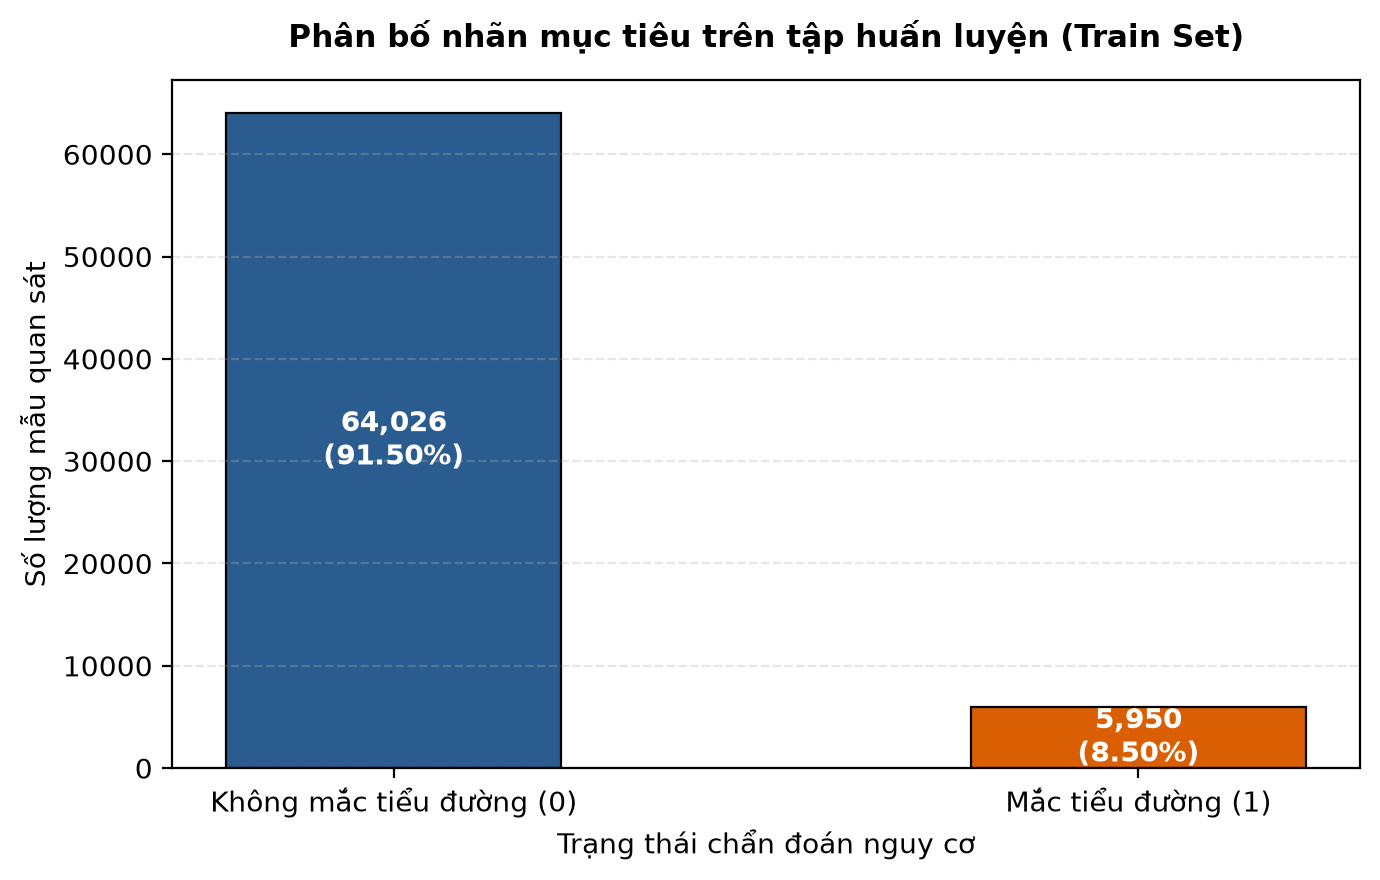

Đã lưu biểu đồ phân bố nhãn: outputs/figures/f_nb01_label_dist.png


In [7]:
# Cell 2.1: Phân bố nhãn mục tiêu Outcome/Diabetes trên tập huấn luyện
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Tạo DataFrame tập Train kết hợp đặc trưng và nhãn
df_train = X_train.copy()
df_train["diabetes"] = y_train.values

# Trực quan hóa phân bố nhãn
plt.figure(figsize=(7, 4.5), dpi=200)
counts = df_train["diabetes"].value_counts().sort_index()
total_samples = len(df_train)

bars = plt.bar(
    ["Không mắc tiểu đường (0)", "Mắc tiểu đường (1)"],
    counts.values,
    color=["#2b5c8f", "#d95f02"],
    width=0.45,
    edgecolor="black",
    linewidth=0.8
)

# Hiển thị số lượng và tỷ lệ % trên đỉnh cột
for bar in bars:
    height = bar.get_height()
    pct = height / total_samples * 100
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height / 2.0,
        f"{int(height):,}\n({pct:.2f}%)",
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=10
    )

plt.title("Phân bố nhãn mục tiêu trên tập huấn luyện (Train Set)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Trạng thái chẩn đoán nguy cơ", fontsize=10)
plt.ylabel("Số lượng mẫu quan sát", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

# Lưu hình theo quy chuẩn mã hóa tệp
fig_path = "outputs/figures/f_nb01_label_dist.png"
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ phân bố nhãn: {fig_path}")

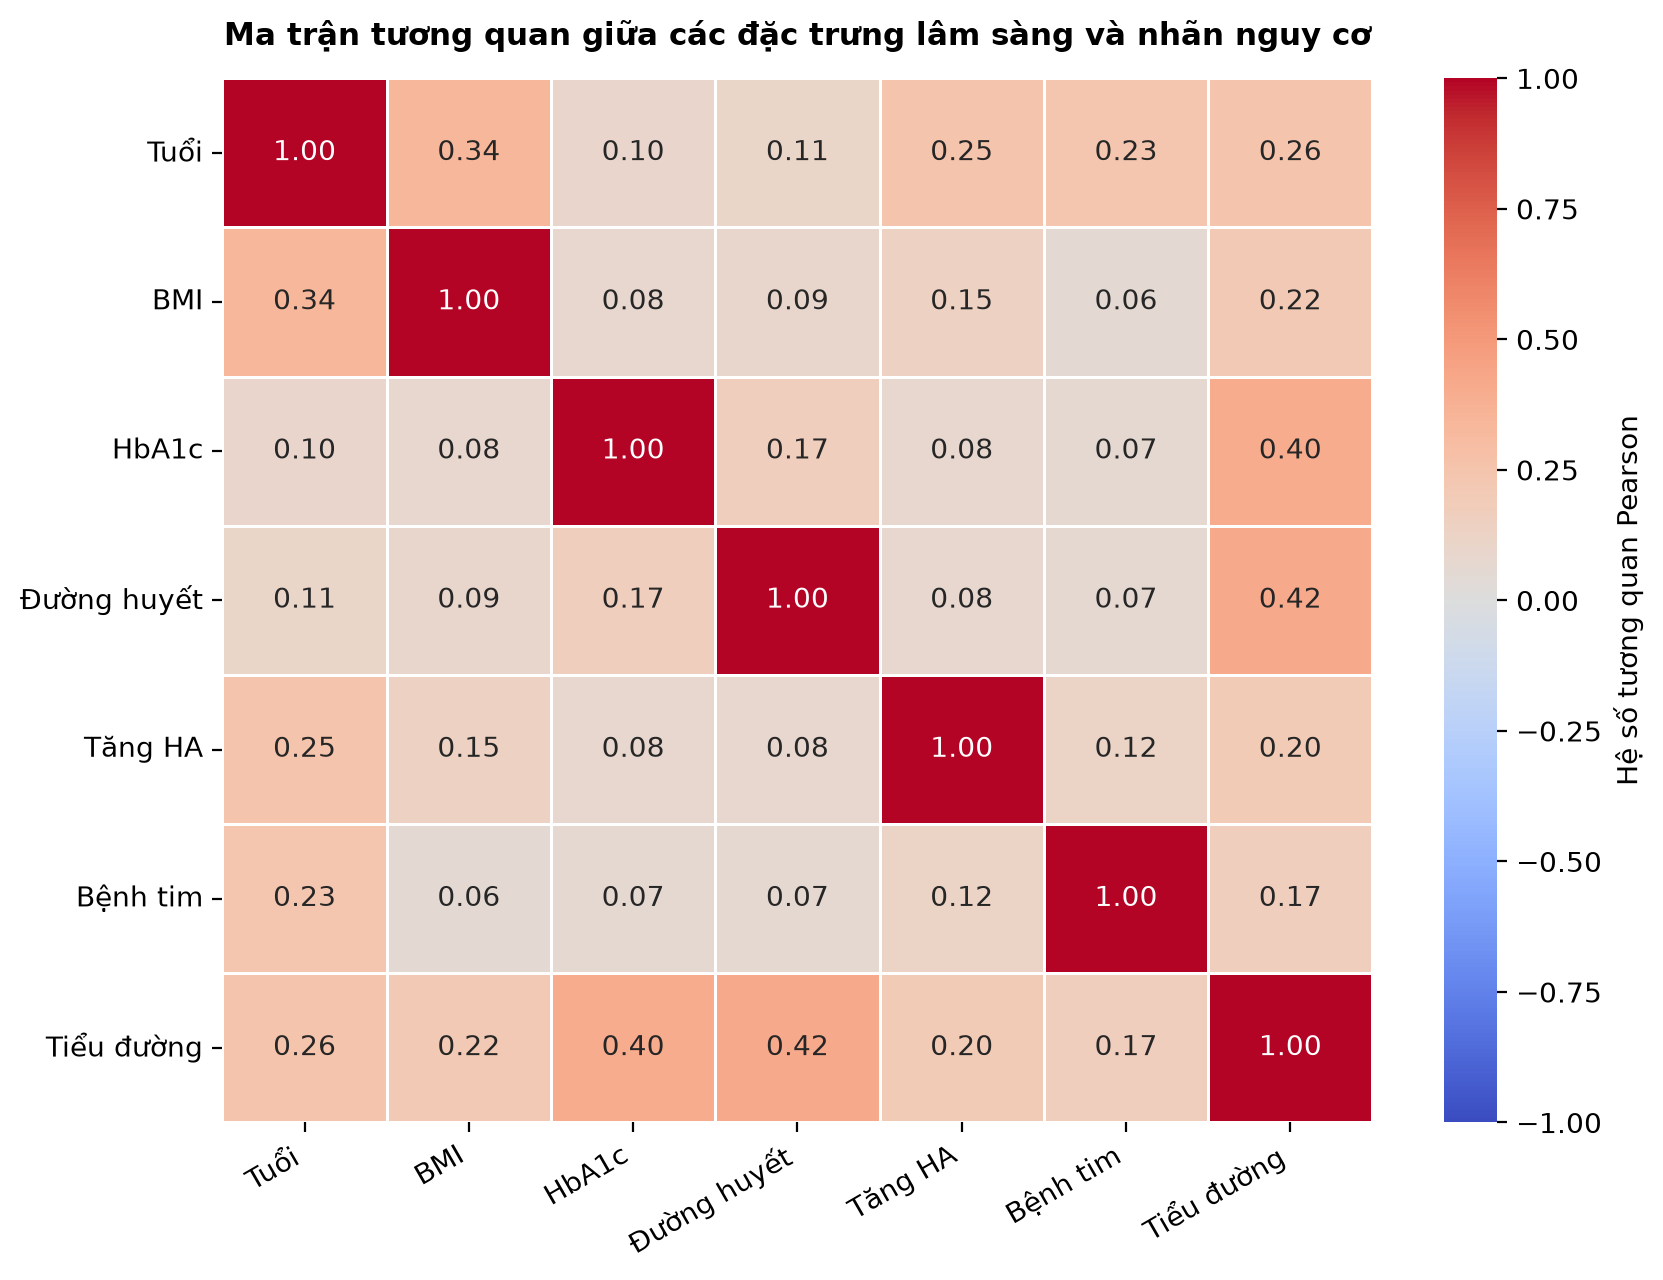

Đã lưu ma trận tương quan: outputs/figures/f_nb01_corr_matrix.png


In [8]:
# Cell 2.2: Ma trận tương quan giữa các biến lâm sàng và nhãn nguy cơ
corr_cols = clinical_num_features + ["hypertension", "heart_disease", "diabetes"]
corr_matrix = df_train[corr_cols].corr(method="pearson")

plt.figure(figsize=(8.5, 6.5), dpi=200)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5,
    cbar_kws={"label": "Hệ số tương quan Pearson"}
)

plt.title("Ma trận tương quan giữa các đặc trưng lâm sàng và nhãn nguy cơ", fontsize=11, fontweight="bold", pad=12)
plt.xticks(
    ticks=np.arange(len(corr_cols)) + 0.5,
    labels=["Tuổi", "BMI", "HbA1c", "Đường huyết", "Tăng HA", "Bệnh tim", "Tiểu đường"],
    rotation=30,
    ha="right"
)
plt.yticks(
    ticks=np.arange(len(corr_cols)) + 0.5,
    labels=["Tuổi", "BMI", "HbA1c", "Đường huyết", "Tăng HA", "Bệnh tim", "Tiểu đường"],
    rotation=0
)
plt.tight_layout()

fig_path = "outputs/figures/f_nb01_corr_matrix.png"
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Đã lưu ma trận tương quan: {fig_path}")

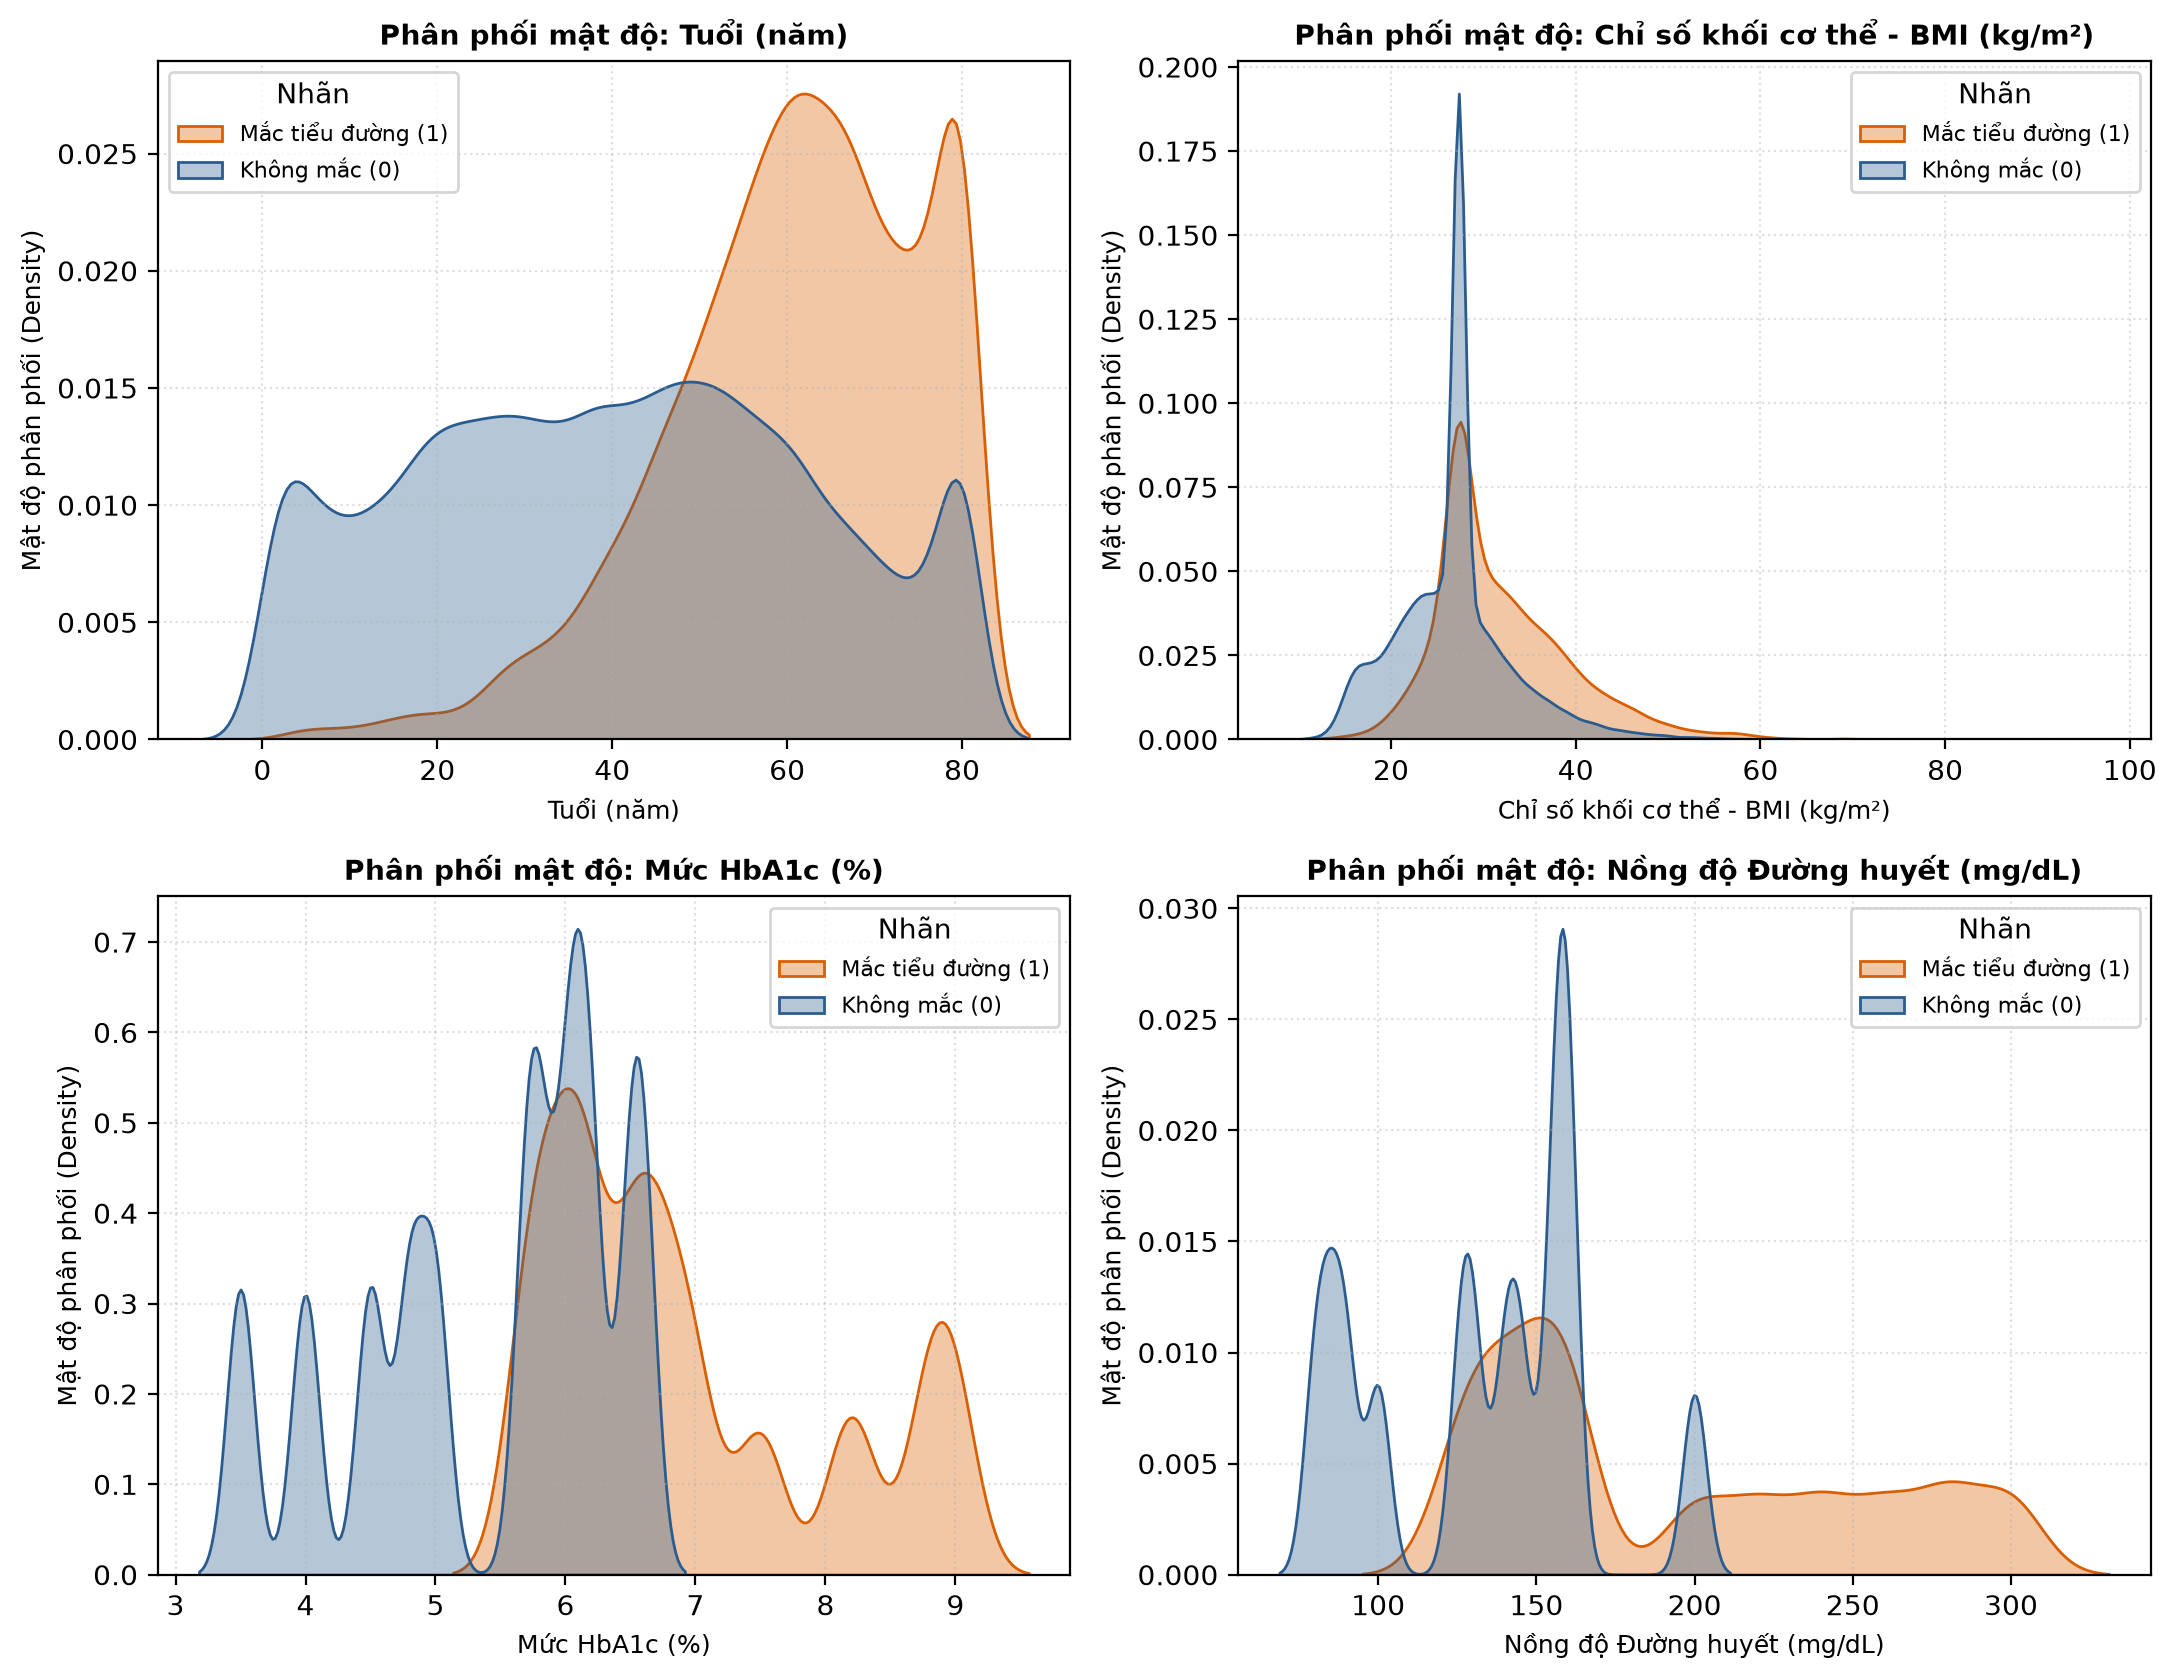

Đã lưu phân phối đặc trưng số học: outputs/figures/f_nb01_feature_dist.png


In [9]:
# Cell 2.3: Phân phối mật độ (KDE) của 4 đặc trưng số học chính theo nhãn
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), dpi=200)

num_features_meta = [
    ("age", "Tuổi (năm)", axes[0, 0]),
    ("bmi", "Chỉ số khối cơ thể - BMI (kg/m²)", axes[0, 1]),
    ("hbA1c_level", "Mức HbA1c (%)", axes[1, 0]),
    ("blood_glucose_level", "Nồng độ Đường huyết (mg/dL)", axes[1, 1])
]

for col, label, ax in num_features_meta:
    sns.kdeplot(
        data=df_train,
        x=col,
        hue="diabetes",
        common_norm=False,
        fill=True,
        alpha=0.35,
        palette=["#2b5c8f", "#d95f02"],
        ax=ax
    )
    ax.set_title(f"Phân phối mật độ: {label}", fontsize=10, fontweight="bold")
    ax.set_xlabel(label, fontsize=9)
    ax.set_ylabel("Mật độ phân phối (Density)", fontsize=9)
    ax.legend(title="Nhãn", labels=["Mắc tiểu đường (1)", "Không mắc (0)"], fontsize=8)
    ax.grid(True, linestyle=":", alpha=0.4)

plt.tight_layout()
fig_path = "outputs/figures/f_nb01_feature_dist.png"
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Đã lưu phân phối đặc trưng số học: {fig_path}")

C:\Users\Huy\AppData\Local\Temp\ipykernel_13688\3048919829.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


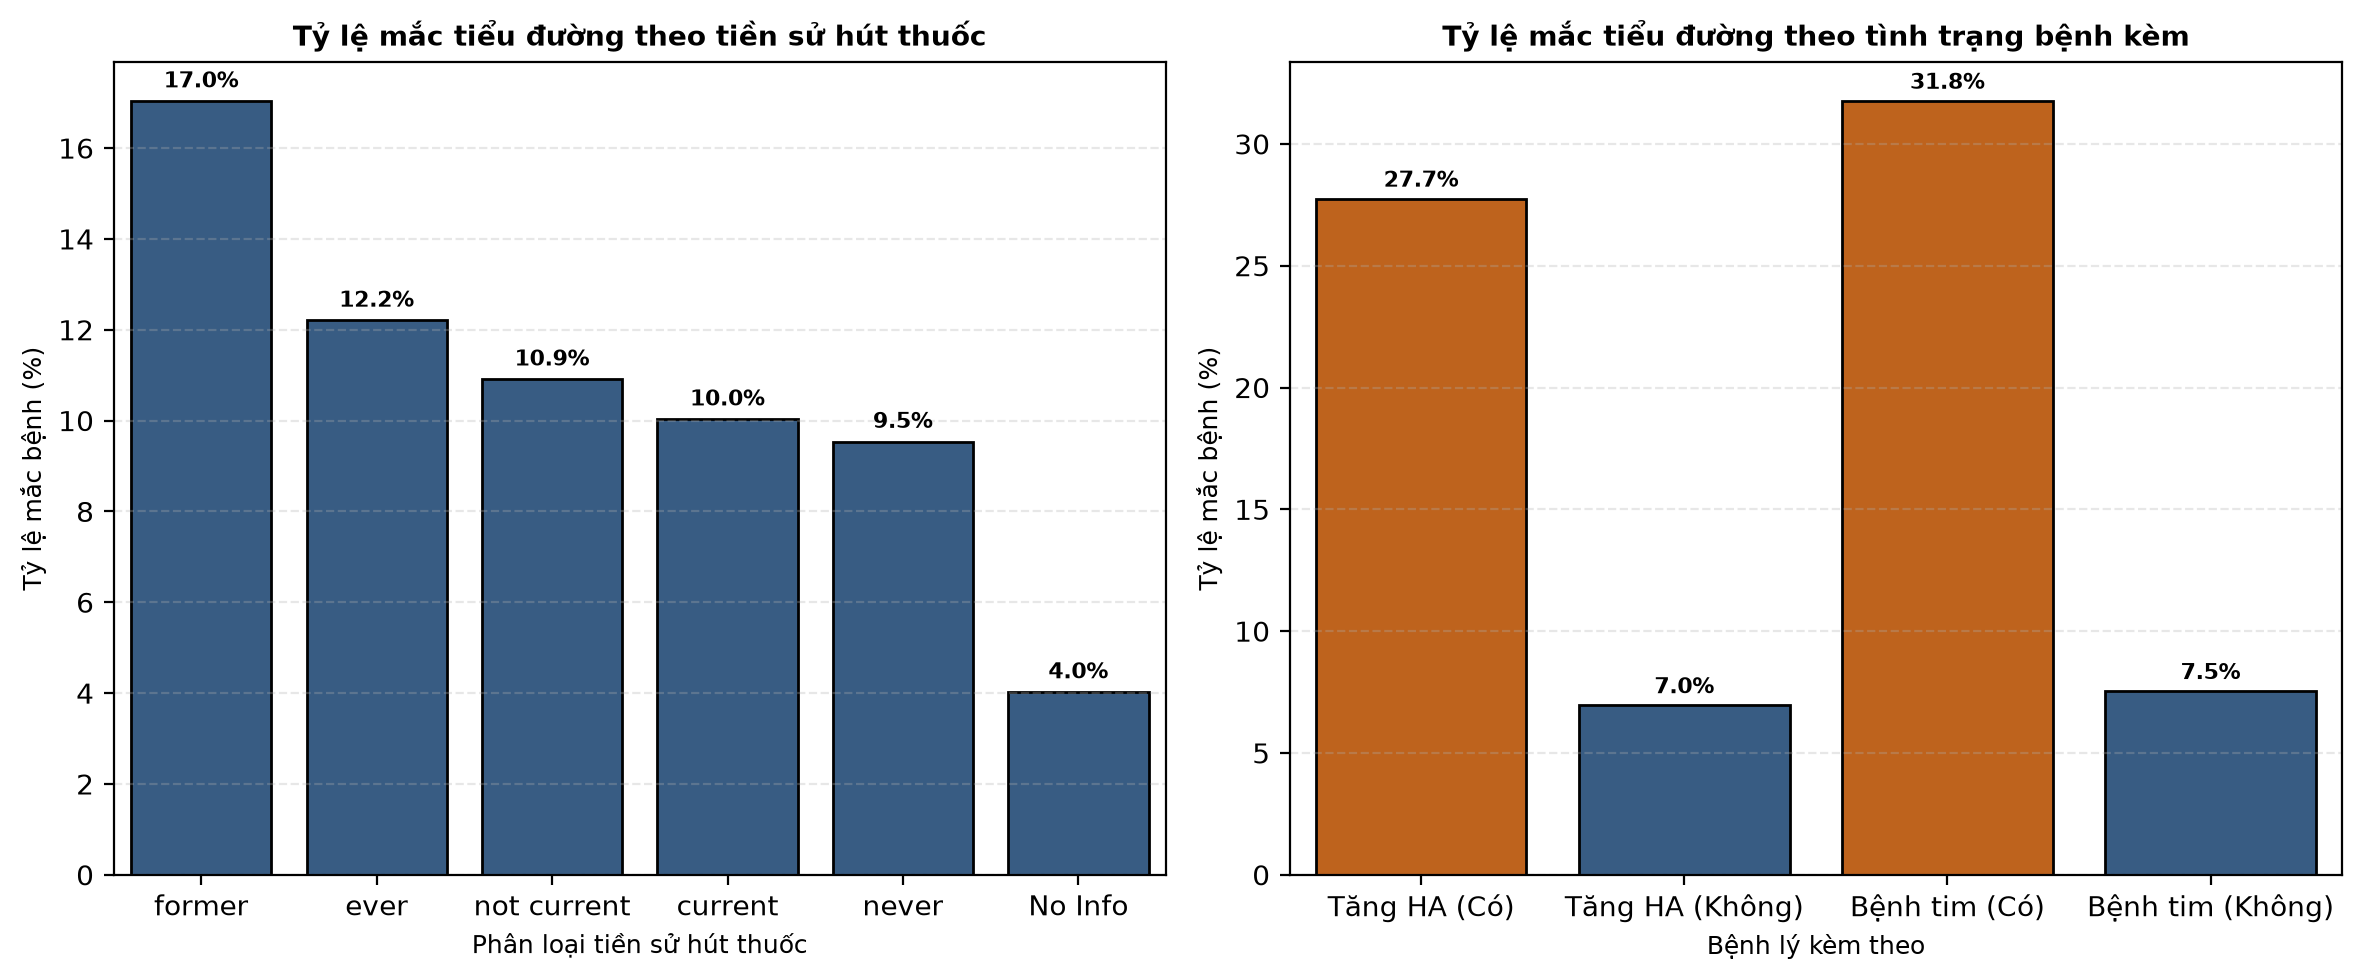

Đã lưu biểu đồ phân tích biến hạng mục: outputs/figures/f_nb01_categorical_dist.png


In [10]:
# Cell 2.4: Phân tích tỷ lệ mắc tiểu đường theo biến hạng mục và bệnh nền
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=200)

# 1. Tỷ lệ theo lịch sử hút thuốc
smoke_summary = df_train.groupby("smoking_history")["diabetes"].agg(["count", "mean"]).reset_index()
smoke_summary["rate_pct"] = smoke_summary["mean"] * 100
smoke_summary = smoke_summary.sort_values(by="rate_pct", ascending=False)

sns.barplot(data=smoke_summary, x="smoking_history", y="rate_pct", ax=axes[0], color="#2b5c8f", edgecolor="black")
axes[0].set_title("Tỷ lệ mắc tiểu đường theo tiền sử hút thuốc", fontsize=10, fontweight="bold")
axes[0].set_xlabel("Phân loại tiền sử hút thuốc", fontsize=9)
axes[0].set_ylabel("Tỷ lệ mắc bệnh (%)", fontsize=9)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)
for p in axes[0].patches:
    h = p.get_height()
    axes[0].annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 0.3), ha="center", fontsize=8, fontweight="bold")

# 2. Tỷ lệ theo tăng huyết áp và bệnh tim mạch
comorbidities = pd.DataFrame({
    "Tình trạng": ["Tăng HA (Có)", "Tăng HA (Không)", "Bệnh tim (Có)", "Bệnh tim (Không)"],
    "Tỷ lệ mắc (%)": [
        df_train[df_train["hypertension"] == 1]["diabetes"].mean() * 100,
        df_train[df_train["hypertension"] == 0]["diabetes"].mean() * 100,
        df_train[df_train["heart_disease"] == 1]["diabetes"].mean() * 100,
        df_train[df_train["heart_disease"] == 0]["diabetes"].mean() * 100
    ]
})

sns.barplot(
    data=comorbidities,
    x="Tình trạng",
    y="Tỷ lệ mắc (%)",
    ax=axes[1],
    palette=["#d95f02", "#2b5c8f", "#d95f02", "#2b5c8f"],
    edgecolor="black"
)
axes[1].set_title("Tỷ lệ mắc tiểu đường theo tình trạng bệnh kèm", fontsize=10, fontweight="bold")
axes[1].set_xlabel("Bệnh lý kèm theo", fontsize=9)
axes[1].set_ylabel("Tỷ lệ mắc bệnh (%)", fontsize=9)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)
for p in axes[1].patches:
    h = p.get_height()
    axes[1].annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 0.5), ha="center", fontsize=8, fontweight="bold")

plt.tight_layout()
fig_path = "outputs/figures/f_nb01_categorical_dist.png"
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ phân tích biến hạng mục: {fig_path}")

In [11]:
# Cell 2.5: Bảng thống kê định lượng các chỉ số sinh học theo nhóm bệnh nhân
group_stats = df_train.groupby("diabetes")[clinical_num_features].agg(
    ["count", "mean", "std", "median", lambda x: np.percentile(x, 75) - np.percentile(x, 25)]
)
group_stats.columns = [f"{col}_{stat}" for col, stat in [
    ("age", "count"), ("age", "mean"), ("age", "std"), ("age", "median"), ("age", "IQR"),
    ("bmi", "count"), ("bmi", "mean"), ("bmi", "std"), ("bmi", "median"), ("bmi", "IQR"),
    ("hbA1c", "count"), ("hbA1c", "mean"), ("hbA1c", "std"), ("hbA1c", "median"), ("hbA1c", "IQR"),
    ("glucose", "count"), ("glucose", "mean"), ("glucose", "std"), ("glucose", "median"), ("glucose", "IQR")
]]

# Định dạng bảng hiển thị trực quan
formatted_summary = []
for label_val, name in [(0, "Không mắc tiểu đường (0)"), (1, "Mắc tiểu đường (1)")]:
    sub = df_train[df_train["diabetes"] == label_val]
    row = {"Nhóm bệnh nhân": name, "Cỡ mẫu (N)": len(sub)}
    for f_col, f_name in [("age", "Tuổi"), ("bmi", "BMI"), ("hbA1c_level", "HbA1c"), ("blood_glucose_level", "Đường huyết")]:
        row[f"{f_name} (Mean ± SD)"] = f"{sub[f_col].mean():.2f} ± {sub[f_col].std():.2f}"
        row[f"{f_name} (Median)"] = f"{sub[f_col].median():.2f}"
    formatted_summary.append(row)

df_eda_summary = pd.DataFrame(formatted_summary)
print("=== BẢNG THỐNG KÊ MÔ TẢ ĐẶC TRƯNG LÂM SÀNG TRÊN TẬP HUẤN LUYỆN ===")
display(df_eda_summary.T)

# Lưu kết quả thống kê mô tả vào file JSON
summary_dict = df_eda_summary.to_dict(orient="records")
summary_file = "outputs/metrics/train_eda_summary.json"
with open(summary_file, "w", encoding="utf-8") as f:
    json.dump(summary_dict, f, indent=4, ensure_ascii=False)
print(f"Đã lưu bảng thống kê EDA vào: {summary_file}")

=== BẢNG THỐNG KÊ MÔ TẢ ĐẶC TRƯNG LÂM SÀNG TRÊN TẬP HUẤN LUYỆN ===


,0,1
Nhóm bệnh nhân,Không mắc tiểu đường (0),Mắc tiểu đường (1)
Cỡ mẫu (N),64026,5950
Tuổi (Mean ± SD),40.10 ± 22.33,60.80 ± 14.48
Tuổi (Median),40.00,62.00
BMI (Mean ± SD),26.86 ± 6.34,31.98 ± 7.58
BMI (Median),27.32,29.99
HbA1c (Mean ± SD),5.40 ± 0.97,6.93 ± 1.07
HbA1c (Median),5.80,6.60
Đường huyết (Mean ± SD),132.86 ± 34.18,193.86 ± 58.86
Đường huyết (Median),140.00,160.00


Đã lưu bảng thống kê EDA vào: outputs/metrics/train_eda_summary.json


In [12]:
# Cell 3.1: Xây dựng đường ống tiền xử lý dữ liệu (ColumnTransformer)
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. Khởi tạo bộ tiền xử lý: Chuẩn hóa biến số học, mã hóa One-Hot biến danh mục
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), clinical_num_features),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), clinical_cat_features),
        ("bin", "passthrough", binary_clinical_features)
    ]
)

# 2. Fit CHỈ trên tập Train, sau đó Transform độc lập cho Train, Val và Test
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

# 3. Trích xuất danh sách tên đặc trưng sau tiền xử lý
feature_names = preprocessor.get_feature_names_out().tolist()

print("=== KẾT QUẢ TIỀN XỬ LÝ KHÔNG RÒ RỈ DỮ LIỆU ===")
print(f"Kích thước X_train sau xử lý : {X_train_proc.shape}")
print(f"Kích thước X_val sau xử lý   : {X_val_proc.shape}")
print(f"Kích thước X_test sau xử lý  : {X_test_proc.shape}")
print(f"Tổng số đặc trưng đầu vào (d): {len(feature_names)}")
print(f"Danh sách đặc trưng: {feature_names}")

=== KẾT QUẢ TIỀN XỬ LÝ KHÔNG RÒ RỈ DỮ LIỆU ===
Kích thước X_train sau xử lý : (69976, 17)
Kích thước X_val sau xử lý   : (14996, 17)
Kích thước X_test sau xử lý  : (14996, 17)
Tổng số đặc trưng đầu vào (d): 17
Danh sách đặc trưng: ['num__age', 'num__bmi', 'num__hbA1c_level', 'num__blood_glucose_level', 'cat__gender_Male', 'cat__smoking_history_current', 'cat__smoking_history_ever', 'cat__smoking_history_former', 'cat__smoking_history_never', 'cat__smoking_history_not current', 'bin__hypertension', 'bin__heart_disease', 'bin__race:AfricanAmerican', 'bin__race:Asian', 'bin__race:Caucasian', 'bin__race:Hispanic', 'bin__race:Other']


In [13]:
# Cell 3.2: Thiết lập các phương án xử lý mất cân bằng lớp trên tập Huấn luyện
from sklearn.utils import resample

# Phương án A: Giữ nguyên phân bố tự nhiên (Baseline không can thiệp)
# Dùng trực tiếp X_train_proc và y_train

# Phương án B: Cost-sensitive learning (Sử dụng class_weight='balanced' trong mô hình)
# Tỷ lệ trọng số tự động nghịch đảo với tần suất xuất hiện của từng lớp

# Phương án C: Random Oversampling tập huấn luyện (Tăng cường mẫu lớp thiểu số)
# LƯU Ý PHƯƠNG PHÁP: Chỉ tái lấy mẫu trên tập Train, tuyệt đối không chạm vào Val hay Test
df_train_temp = pd.DataFrame(X_train_proc, columns=feature_names)
df_train_temp["target"] = y_train.values

df_majority = df_train_temp[df_train_temp["target"] == 0]
df_minority = df_train_temp[df_train_temp["target"] == 1]

df_minority_oversampled = resample(
    df_minority,
    replace=True,
    n_samples=len(df_majority),
    random_state=SEED
)

df_train_oversampled = pd.concat([df_majority, df_minority_oversampled], axis=0).sample(frac=1.0, random_state=SEED).reset_index(drop=True)

X_train_os = df_train_oversampled.drop(columns=["target"]).values
y_train_os = df_train_oversampled["target"].values

print("=== CÁC CHIẾN LƯỢC XỬ LÝ MẤT CÂN BẰNG ĐƯỢC THIẾT LẬP ===")
print(f"1. Phân bố gốc (Unweighted)    : Lớp 0 = {(y_train == 0).sum():,}, Lớp 1 = {(y_train == 1).sum():,} (Tổng: {len(y_train):,})")
print(f"2. Trọng số lớp (Class Weight) : Tính trực tiếp trong hàm mục tiêu")
print(f"3. Oversampling (Train Only)   : Lớp 0 = {(y_train_os == 0).sum():,}, Lớp 1 = {(y_train_os == 1).sum():,} (Tổng: {len(y_train_os):,})")

=== CÁC CHIẾN LƯỢC XỬ LÝ MẤT CÂN BẰNG ĐƯỢC THIẾT LẬP ===
1. Phân bố gốc (Unweighted)    : Lớp 0 = 64,026, Lớp 1 = 5,950 (Tổng: 69,976)
2. Trọng số lớp (Class Weight) : Tính trực tiếp trong hàm mục tiêu
3. Oversampling (Train Only)   : Lớp 0 = 64,026, Lớp 1 = 64,026 (Tổng: 128,052)


In [14]:
# Cell 3.3: Huấn luyện Baseline 1 - Hồi quy Logistic (Logistic Regression)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

def evaluate_on_validation(model, X_v, y_v, model_title: str, imbal_method: str):
    """Đánh giá mô hình trên tập Validation tại ngưỡng mặc định 0.5 và ngưỡng tối ưu F1."""
    probs = model.predict_proba(X_v)[:, 1]
    
    # 1. Đo lường tại ngưỡng mặc định 0.5
    preds_def = (probs >= 0.5).astype(int)
    
    # 2. Dò tìm ngưỡng tối ưu trên tập Validation theo đúng Giao thức Chặng 1
    threshold_grid = np.linspace(0.05, 0.95, 91)
    best_th = 0.5
    best_f1 = 0.0
    for th in threshold_grid:
        p_th = (probs >= th).astype(int)
        score_f1 = f1_score(y_v, p_th, zero_division=0)
        if score_f1 > best_f1:
            best_f1 = score_f1
            best_th = th
            
    preds_opt = (probs >= best_th).astype(int)
    
    return {
        "model": model_title,
        "imbalance_handling": imbal_method,
        "roc_auc": round(float(roc_auc_score(y_v, probs)), 4),
        "pr_auc": round(float(average_precision_score(y_v, probs)), 4),
        "threshold_default": 0.5,
        "accuracy_default": round(float(accuracy_score(y_v, preds_def)), 4),
        "precision_default": round(float(precision_score(y_v, preds_def, zero_division=0)), 4),
        "recall_default": round(float(recall_score(y_v, preds_def, zero_division=0)), 4),
        "f1_default": round(float(f1_score(y_v, preds_def, zero_division=0)), 4),
        "threshold_optimal": round(float(best_th), 2),
        "accuracy_optimal": round(float(accuracy_score(y_v, preds_opt)), 4),
        "precision_optimal": round(float(precision_score(y_v, preds_opt, zero_division=0)), 4),
        "recall_optimal": round(float(recall_score(y_v, preds_opt, zero_division=0)), 4),
        "f1_optimal": round(float(best_f1), 4)
    }

# Huấn luyện 3 biến thể Logistic Regression
lr_unweighted = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_proc, y_train)
lr_weighted = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED).fit(X_train_proc, y_train)
lr_oversampled = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_os, y_train_os)

lr_results = [
    evaluate_on_validation(lr_unweighted, X_val_proc, y_val, "Logistic Regression", "Không can thiệp (Unweighted)"),
    evaluate_on_validation(lr_weighted, X_val_proc, y_val, "Logistic Regression", "Trọng số lớp (Class Weight)"),
    evaluate_on_validation(lr_oversampled, X_val_proc, y_val, "Logistic Regression", "Tái lấy mẫu (Oversampling)")
]

df_lr_eval = pd.DataFrame(lr_results)
print("=== KẾT QUẢ ĐÁNH GIÁ BASELINE 1 (LOGISTIC REGRESSION) TRÊN TẬP VALIDATION ===")
display(df_lr_eval[["imbalance_handling", "pr_auc", "roc_auc", "f1_default", "threshold_optimal", "f1_optimal", "recall_optimal"]])

=== KẾT QUẢ ĐÁNH GIÁ BASELINE 1 (LOGISTIC REGRESSION) TRÊN TẬP VALIDATION ===


,imbalance_handling,pr_auc,roc_auc,f1_default,threshold_optimal,f1_optimal,recall_optimal
0,Không can thiệp (Unweighted),0.8256,0.9633,0.7323,0.41,0.7448,0.6831
1,Trọng số lớp (Class Weight),0.8253,0.9636,0.5668,0.87,0.7418,0.6996
2,Tái lấy mẫu (Oversampling),0.8252,0.9636,0.5656,0.87,0.7426,0.7004


In [15]:
# Cell 3.4: Huấn luyện Baseline 2 - Rừng ngẫu nhiên (Random Forest)
from sklearn.ensemble import RandomForestClassifier

# Huấn luyện 3 biến thể Random Forest
rf_unweighted = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=SEED, n_jobs=-1).fit(X_train_proc, y_train)
rf_weighted = RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced", random_state=SEED, n_jobs=-1).fit(X_train_proc, y_train)
rf_oversampled = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=SEED, n_jobs=-1).fit(X_train_os, y_train_os)

rf_results = [
    evaluate_on_validation(rf_unweighted, X_val_proc, y_val, "Random Forest", "Không can thiệp (Unweighted)"),
    evaluate_on_validation(rf_weighted, X_val_proc, y_val, "Random Forest", "Trọng số lớp (Class Weight)"),
    evaluate_on_validation(rf_oversampled, X_val_proc, y_val, "Random Forest", "Tái lấy mẫu (Oversampling)")
]

df_rf_eval = pd.DataFrame(rf_results)
print("=== KẾT QUẢ ĐÁNH GIÁ BASELINE 2 (RANDOM FOREST) TRÊN TẬP VALIDATION ===")
display(df_rf_eval[["imbalance_handling", "pr_auc", "roc_auc", "f1_default", "threshold_optimal", "f1_optimal", "recall_optimal"]])

=== KẾT QUẢ ĐÁNH GIÁ BASELINE 2 (RANDOM FOREST) TRÊN TẬP VALIDATION ===


,imbalance_handling,pr_auc,roc_auc,f1_default,threshold_optimal,f1_optimal,recall_optimal
0,Không can thiệp (Unweighted),0.8804,0.9729,0.8039,0.32,0.8128,0.6965
1,Trọng số lớp (Class Weight),0.8825,0.9761,0.6264,0.84,0.8099,0.6902
2,Tái lấy mẫu (Oversampling),0.8826,0.9762,0.6231,0.85,0.8111,0.6871


Đã lưu bảng số liệu đánh giá Baselines vào: outputs/metrics/nb01_baseline_val_metrics.json


C:\Users\Huy\AppData\Local\Temp\ipykernel_13688\1787220445.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plot_df, x="model_tag", y="pr_auc", ax=axes[0], palette="Blues_r", edgecolor="black")


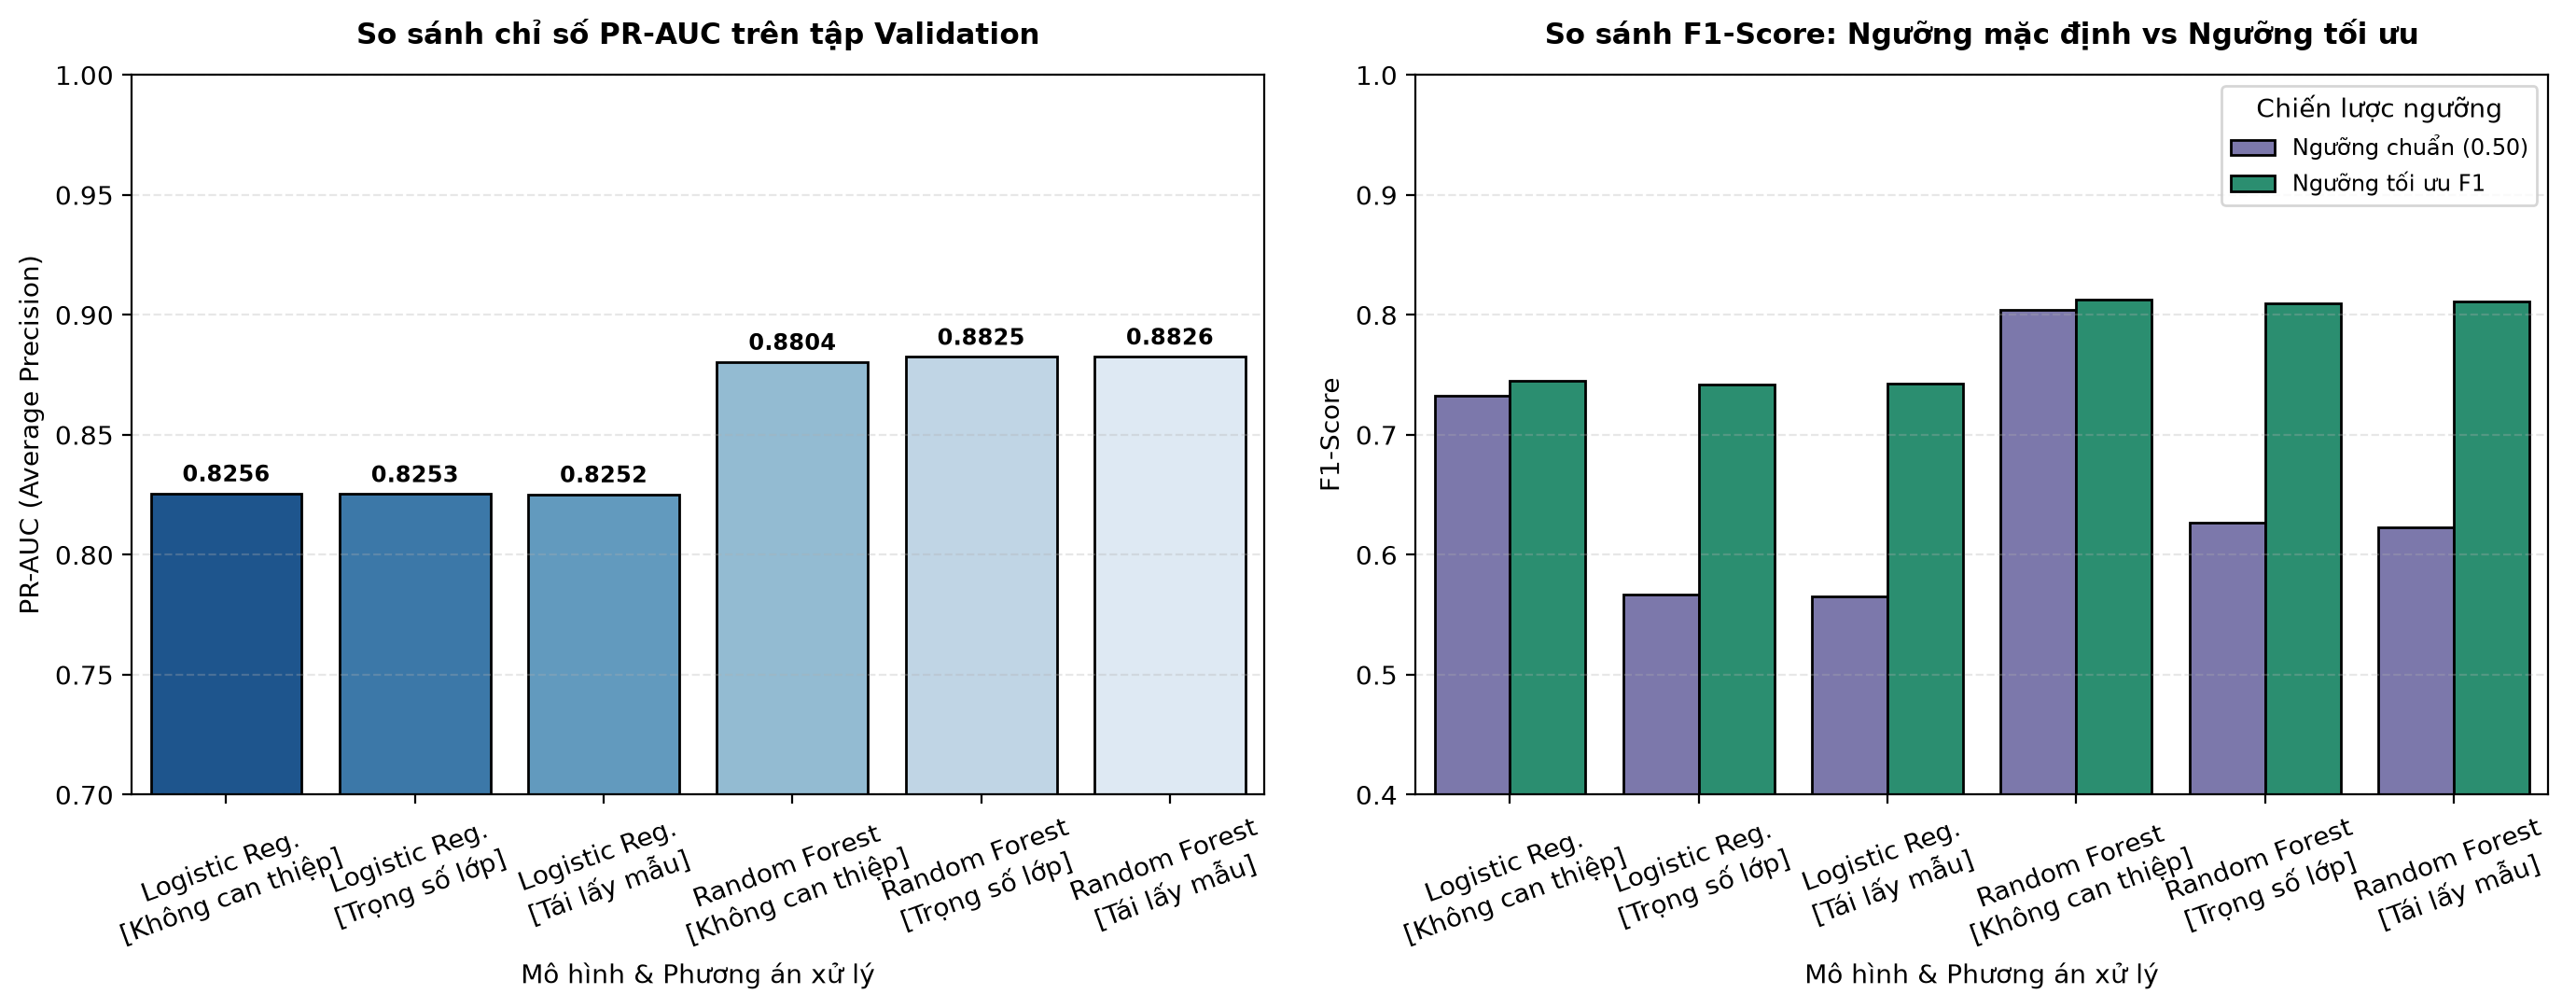

Đã lưu biểu đồ so sánh Baseline: outputs/figures/f_nb01_baseline_val_comparison.png


In [17]:
# Cell 3.5: Tổng hợp so sánh Baseline, lưu JSON chỉ số và xuất hình ảnh kỹ thuật (Đã sửa hiển thị)
import os
import json
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Cấu hình phông chữ hỗ trợ trọn vẹn tiếng Việt Unicode và khử lỗi dấu âm
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# 2. Tổng hợp kết quả đánh giá validation
all_baseline_results = lr_results + rf_results
df_all_baselines = pd.DataFrame(all_baseline_results)

# 3. Lưu kết quả ra file JSON
os.makedirs("outputs/metrics", exist_ok=True)
metrics_path = "outputs/metrics/nb01_baseline_val_metrics.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(all_baseline_results, f, indent=4, ensure_ascii=False)
print(f"Đã lưu bảng số liệu đánh giá Baselines vào: {metrics_path}")

# 4. Trực quan hóa đối sánh PR-AUC và F1-Score
os.makedirs("outputs/figures", exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=200)

plot_df = df_all_baselines.copy()
# Định dạng nhãn trục x ngắn gọn, rõ ràng để chống đè chữ
plot_df["model_tag"] = plot_df["model"].replace({
    "Logistic Regression": "Logistic Reg.",
    "Random Forest": "Random Forest"
}) + "\n[" + plot_df["imbalance_handling"].str.split("(").str[0].str.strip() + "]"

# Đồ thị a: PR-AUC (Chỉ số lựa chọn mô hình cốt lõi)
sns.barplot(data=plot_df, x="model_tag", y="pr_auc", ax=axes[0], palette="Blues_r", edgecolor="black")
axes[0].set_title("So sánh chỉ số PR-AUC trên tập Validation", fontsize=11, fontweight="bold", pad=12)
axes[0].set_xlabel("Mô hình & Phương án xử lý", fontsize=10)
axes[0].set_ylabel("PR-AUC (Average Precision)", fontsize=10)
axes[0].set_ylim(0.70, 1.0)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)
axes[0].tick_params(axis="x", rotation=20)
for p in axes[0].patches:
    h = p.get_height()
    axes[0].annotate(f"{h:.4f}", (p.get_x() + p.get_width() / 2., h + 0.005), ha="center", fontsize=8.5, fontweight="bold")

# Đồ thị b: F1-Score tại ngưỡng mặc định vs ngưỡng tối ưu
melted_f1 = pd.melt(
    plot_df,
    id_vars=["model_tag"],
    value_vars=["f1_default", "f1_optimal"],
    var_name="threshold_strategy",
    value_name="f1_val"
)
melted_f1["threshold_strategy"] = melted_f1["threshold_strategy"].map({
    "f1_default": "Ngưỡng chuẩn (0.50)",
    "f1_optimal": "Ngưỡng tối ưu F1"
})

sns.barplot(data=melted_f1, x="model_tag", y="f1_val", hue="threshold_strategy", ax=axes[1], palette=["#7570b3", "#1b9e77"], edgecolor="black")
axes[1].set_title("So sánh F1-Score: Ngưỡng mặc định vs Ngưỡng tối ưu", fontsize=11, fontweight="bold", pad=12)
axes[1].set_xlabel("Mô hình & Phương án xử lý", fontsize=10)
axes[1].set_ylabel("F1-Score", fontsize=10)
axes[1].set_ylim(0.40, 1.0)
axes[1].legend(title="Chiến lược ngưỡng", fontsize=8.5)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
fig_comp_path = "outputs/figures/f_nb01_baseline_val_comparison.png"
plt.savefig(fig_comp_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ so sánh Baseline: {fig_comp_path}")

In [18]:
# Cell 4.1: Chuyển đổi dữ liệu sang PyTorch DataLoader và cấu hình trọng số phạt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 1. Xác định thiết bị tính toán (CPU hoặc GPU nếu có)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị tính toán đang kích hoạt: {device}")

# 2. Chuyển đổi ma trận đặc trưng và nhãn sang Tensor PyTorch
X_train_tensor = torch.tensor(X_train_proc, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_proc, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32)

# 3. Đóng gói vào Dataset và DataLoader
BATCH_SIZE = 256
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)

# 4. Tính toán trọng số lớp dương (pos_weight) dựa trên phân bố của tập Train
num_negatives = (y_train == 0).sum()
num_positives = (y_train == 1).sum()
pos_weight_value = float(num_negatives / num_positives)
pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32).to(device)

print(f"Số lượng nhãn âm tính (0) trên tập Train : {num_negatives:,}")
print(f"Số lượng nhãn dương tính (1) trên tập Train: {num_positives:,}")
print(f"Trọng số phạt ca bệnh (pos_weight)        : {pos_weight_value:.4f}")

Thiết bị tính toán đang kích hoạt: cpu
Số lượng nhãn âm tính (0) trên tập Train : 64,026
Số lượng nhãn dương tính (1) trên tập Train: 5,950
Trọng số phạt ca bệnh (pos_weight)        : 10.7607


In [19]:
# Cell 4.2: Định nghĩa kiến trúc mạng nơ-ron sâu DiabetesMLP
import torch.nn as nn

class DiabetesMLP(nn.Module):
    """
    Kiến trúc Deep MLP 3 tầng dành cho bài toán phân loại nguy cơ tiểu đường.
    Đầu vào: Vector đặc trưng 17 chiều
    Đầu ra: Logit nguy cơ (chưa qua sigmoid) để kết hợp ổn định với BCEWithLogitsLoss
    """
    def __init__(self, input_dim: int = 17, hidden_dim1: int = 64, hidden_dim2: int = 32, dropout_rate: float = 0.2):
        super(DiabetesMLP, self).__init__()
        
        # Khối ẩn thứ nhất
        self.block1 = nn.Sequential(
            nn.Linear(input_dim, hidden_dim1),
            nn.BatchNorm1d(hidden_dim1),
            nn.ReLU(),
            nn.Dropout(dropout_rate)
        )
        
        # Khối ẩn thứ hai
        self.block2 = nn.Sequential(
            nn.Linear(hidden_dim1, hidden_dim2),
            nn.BatchNorm1d(hidden_dim2),
            nn.ReLU(),
            nn.Dropout(dropout_rate)
        )
        
        # Tầng phân loại đầu ra
        self.classifier = nn.Linear(hidden_dim2, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h1 = self.block1(x)
        h2 = self.block2(h1)
        logits = self.classifier(h2).squeeze(-1)
        return logits

# Khởi tạo mô hình và in cấu trúc mạng
set_seed(SEED)
mlp_model = DiabetesMLP(input_dim=len(feature_names), hidden_dim1=64, hidden_dim2=32, dropout_rate=0.2).to(device)
print("=== THIẾT KẾ KIẾN TRÚC MÔ HÌNH MLP ===")
print(mlp_model)

total_params = sum(p.numel() for p in mlp_model.parameters() if p.requires_grad)
print(f"\nTổng số tham số có thể huấn luyện (Trainable Parameters): {total_params:,}")

=== THIẾT KẾ KIẾN TRÚC MÔ HÌNH MLP ===
DiabetesMLP(
  (block1): Sequential(
    (0): Linear(in_features=17, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
  )
  (block2): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
  )
  (classifier): Linear(in_features=32, out_features=1, bias=True)
)

Tổng số tham số có thể huấn luyện (Trainable Parameters): 3,457


In [22]:
# Cell 4.3: Vòng lặp huấn luyện mô hình MLP kết hợp Early Stopping (Đã sửa lỗi PyTorch mới)
import copy
import os
import torch.optim as optim
from sklearn.metrics import average_precision_score

# 1. Cấu hình tiêu chí mất mát và bộ tối ưu hóa
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
optimizer = optim.AdamW(mlp_model.parameters(), lr=1e-3, weight_decay=1e-4)

# Loại bỏ tham số verbose=True để tương thích tuyệt đối với các bản PyTorch mới
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

# 2. Cấu hình tham số huấn luyện và Early Stopping
NUM_EPOCHS = 35
PATIENCE = 7
patience_counter = 0
best_val_pr_auc = -1.0
best_epoch = 0
best_model_state = None

history = {
    "train_loss": [],
    "val_loss": [],
    "train_pr_auc": [],
    "val_pr_auc": []
}

print("=== BẮT ĐẦU QUÁ TRÌNH HUẤN LUYỆN PYTORCH MLP ===")
for epoch in range(1, NUM_EPOCHS + 1):
    # --- PHA HUẤN LUYỆN (TRAINING) ---
    mlp_model.train()
    running_train_loss = 0.0
    all_train_probs = []
    all_train_targets = []
    
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        
        logits = mlp_model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item() * len(batch_y)
        probs = torch.sigmoid(logits).detach().cpu().numpy()
        all_train_probs.extend(probs)
        all_train_targets.extend(batch_y.cpu().numpy())
        
    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    epoch_train_pr_auc = average_precision_score(all_train_targets, all_train_probs)
    
    # --- PHA KIỂM ĐỊNH (VALIDATION) ---
    mlp_model.eval()
    running_val_loss = 0.0
    all_val_probs = []
    all_val_targets = []
    
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            logits = mlp_model(batch_x)
            loss = criterion(logits, batch_y)
            
            running_val_loss += loss.item() * len(batch_y)
            probs = torch.sigmoid(logits).cpu().numpy()
            all_val_probs.extend(probs)
            all_val_targets.extend(batch_y.cpu().numpy())
            
    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    epoch_val_pr_auc = average_precision_score(all_val_targets, all_val_probs)
    
    # Cập nhật Scheduler theo chỉ số cốt lõi PR-AUC và theo dõi Learning Rate
    old_lr = optimizer.param_groups[0]["lr"]
    scheduler.step(epoch_val_pr_auc)
    new_lr = optimizer.param_groups[0]["lr"]
    if new_lr < old_lr:
        print(f"--> [Hạ Learning Rate] Giảm tốc độ học từ {old_lr:.6f} xuống {new_lr:.6f}")
    
    # Lưu nhật ký huấn luyện
    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["train_pr_auc"].append(epoch_train_pr_auc)
    history["val_pr_auc"].append(epoch_val_pr_auc)
    
    # Kiểm tra cải thiện và kích hoạt Early Stopping
    if epoch_val_pr_auc > best_val_pr_auc:
        best_val_pr_auc = epoch_val_pr_auc
        best_epoch = epoch
        best_model_state = copy.deepcopy(mlp_model.state_dict())
        patience_counter = 0
        save_marker = "*"
    else:
        patience_counter += 1
        save_marker = " "
        
    print(f"Epoch {epoch:02d}/{NUM_EPOCHS:02d} | Train Loss: {epoch_train_loss:.4f} - PR-AUC: {epoch_train_pr_auc:.4f} | Val Loss: {epoch_val_loss:.4f} - Val PR-AUC: {epoch_val_pr_auc:.4f} {save_marker} (Patience: {patience_counter}/{PATIENCE})")
    
    if patience_counter >= PATIENCE:
        print(f"\n[Kích hoạt Early Stopping] Dừng sớm tại Epoch {epoch}. Mô hình tốt nhất ghi nhận ở Epoch {best_epoch}.")
        break

# Lưu checkpoint mô hình PyTorch tốt nhất vào thư mục outputs/models/
os.makedirs("outputs/models", exist_ok=True)
best_model_path = "outputs/models/best_mlp_model.pt"
torch.save(best_model_state, best_model_path)
print(f"Đã lưu checkpoint mô hình tối ưu vào: {best_model_path}")

=== BẮT ĐẦU QUÁ TRÌNH HUẤN LUYỆN PYTORCH MLP ===
Epoch 01/35 | Train Loss: 0.6153 - PR-AUC: 0.7246 | Val Loss: 0.4533 - Val PR-AUC: 0.8280 * (Patience: 0/7)
Epoch 02/35 | Train Loss: 0.4625 - PR-AUC: 0.7968 | Val Loss: 0.4109 - Val PR-AUC: 0.8413 * (Patience: 0/7)
Epoch 03/35 | Train Loss: 0.4284 - PR-AUC: 0.8159 | Val Loss: 0.3904 - Val PR-AUC: 0.8514 * (Patience: 0/7)
Epoch 04/35 | Train Loss: 0.4115 - PR-AUC: 0.8277 | Val Loss: 0.3801 - Val PR-AUC: 0.8589 * (Patience: 0/7)
Epoch 05/35 | Train Loss: 0.4000 - PR-AUC: 0.8356 | Val Loss: 0.3718 - Val PR-AUC: 0.8632 * (Patience: 0/7)
Epoch 06/35 | Train Loss: 0.3910 - PR-AUC: 0.8402 | Val Loss: 0.3677 - Val PR-AUC: 0.8677 * (Patience: 0/7)
Epoch 07/35 | Train Loss: 0.3851 - PR-AUC: 0.8463 | Val Loss: 0.3614 - Val PR-AUC: 0.8703 * (Patience: 0/7)
Epoch 08/35 | Train Loss: 0.3824 - PR-AUC: 0.8452 | Val Loss: 0.3624 - Val PR-AUC: 0.8699   (Patience: 1/7)
Epoch 09/35 | Train Loss: 0.3793 - PR-AUC: 0.8488 | Val Loss: 0.3602 - Val PR-AUC: 0.87

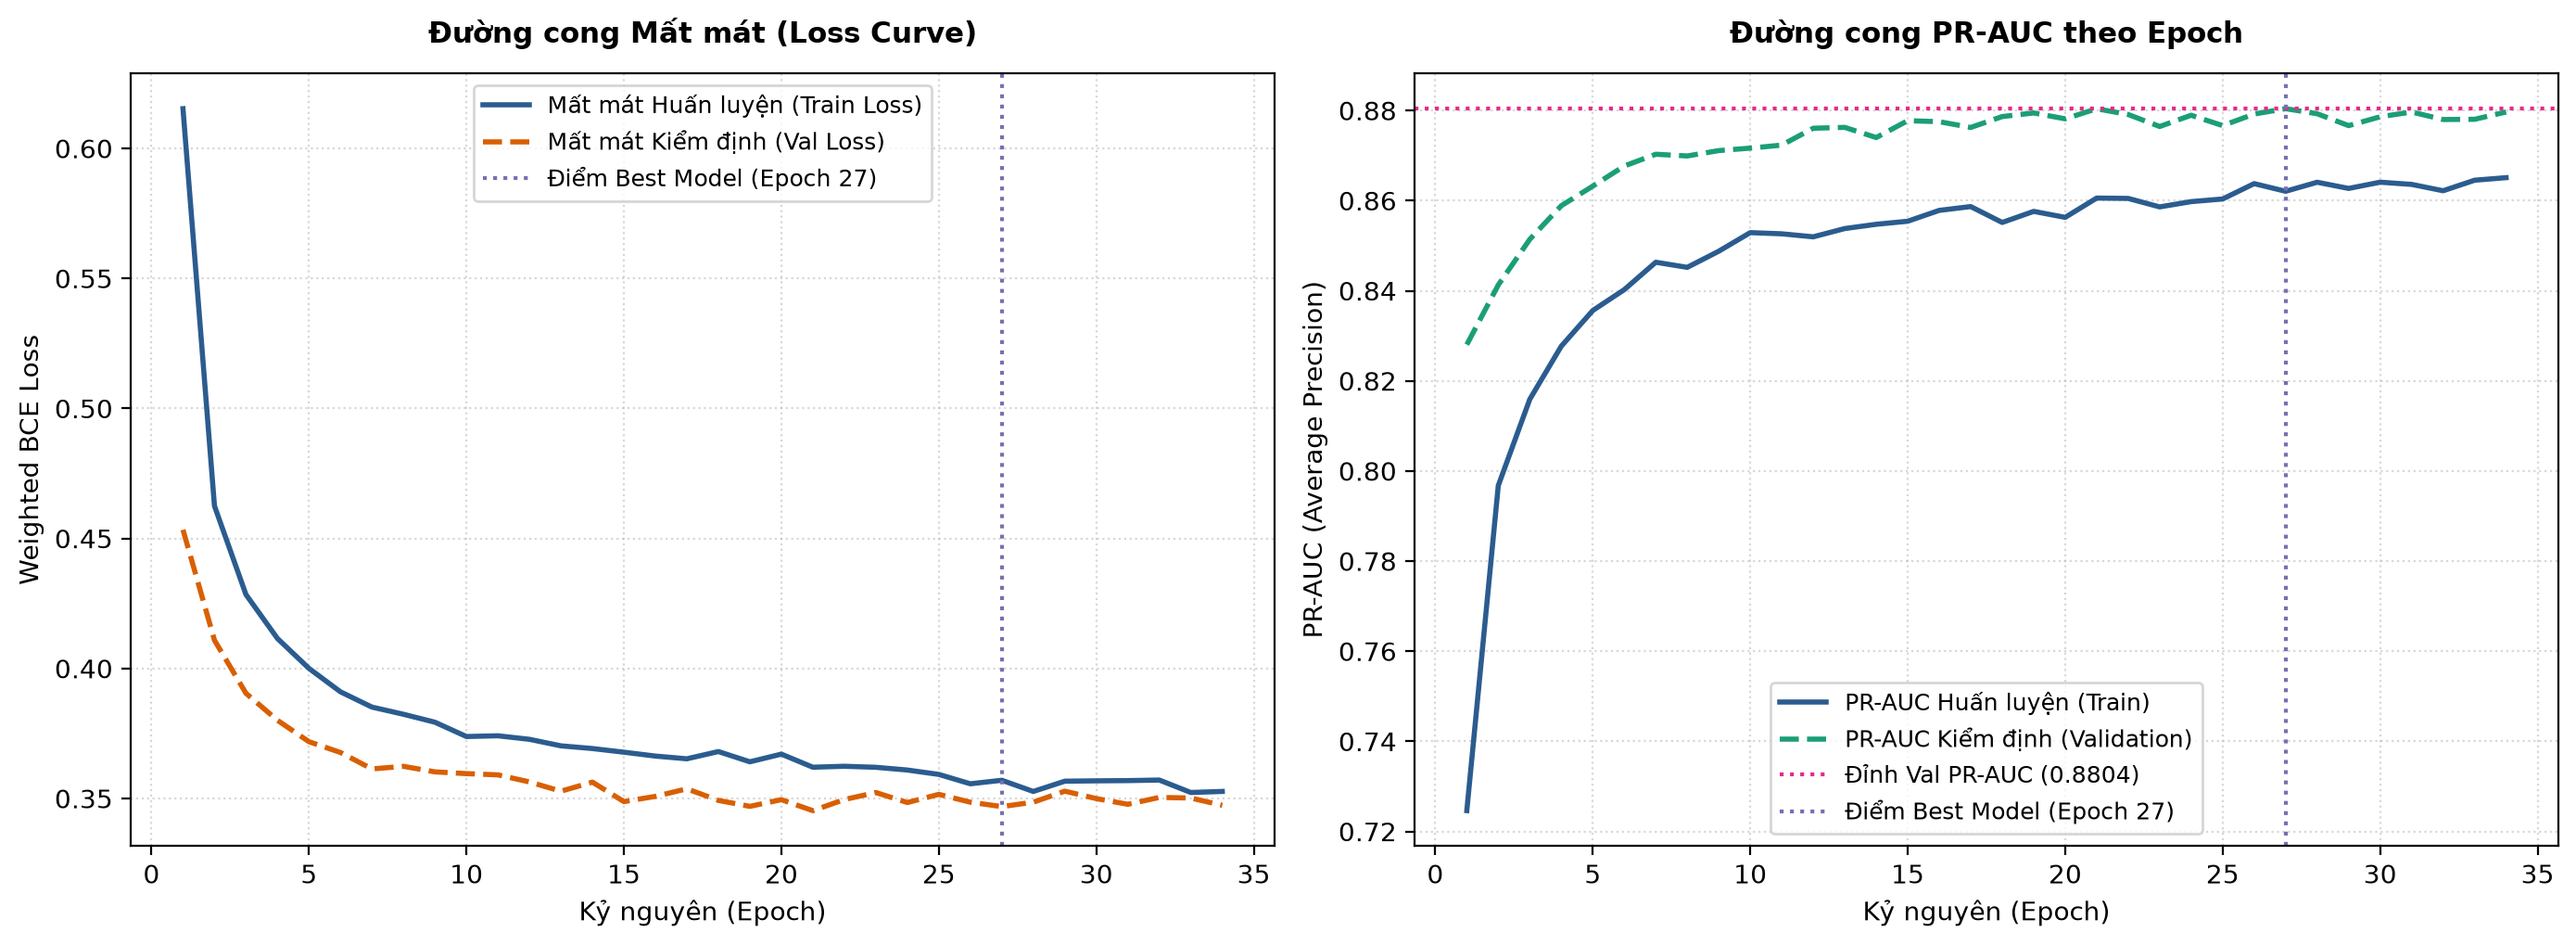

Đã lưu đường học huấn luyện: outputs/figures/f_nb01_learning_curves.png


In [23]:
# Cell 4.4: Trực quan hóa đường học (Learning Curves) và lưu tệp hình ảnh kỹ thuật
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

os.makedirs("outputs/figures", exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), dpi=200)
epochs_range = range(1, len(history["train_loss"]) + 1)

# 1. Đồ thị diễn biến hàm mất mát (Loss Curves)
axes[0].plot(epochs_range, history["train_loss"], label="Mất mát Huấn luyện (Train Loss)", color="#2b5c8f", lw=2)
axes[0].plot(epochs_range, history["val_loss"], label="Mất mát Kiểm định (Val Loss)", color="#d95f02", lw=2, linestyle="--")
axes[0].axvline(x=best_epoch, color="#7570b3", linestyle=":", lw=1.5, label=f"Điểm Best Model (Epoch {best_epoch})")
axes[0].set_title("Đường cong Mất mát (Loss Curve)", fontsize=11, fontweight="bold", pad=12)
axes[0].set_xlabel("Kỷ nguyên (Epoch)", fontsize=10)
axes[0].set_ylabel("Weighted BCE Loss", fontsize=10)
axes[0].legend(fontsize=9)
axes[0].grid(True, linestyle=":", alpha=0.5)

# 2. Đồ thị chỉ số cốt lõi PR-AUC (Average Precision Curves)
axes[1].plot(epochs_range, history["train_pr_auc"], label="PR-AUC Huấn luyện (Train)", color="#2b5c8f", lw=2)
axes[1].plot(epochs_range, history["val_pr_auc"], label="PR-AUC Kiểm định (Validation)", color="#1b9e77", lw=2, linestyle="--")
axes[1].axhline(y=best_val_pr_auc, color="#e7298a", linestyle=":", lw=1.5, label=f"Đỉnh Val PR-AUC ({best_val_pr_auc:.4f})")
axes[1].axvline(x=best_epoch, color="#7570b3", linestyle=":", lw=1.5, label=f"Điểm Best Model (Epoch {best_epoch})")
axes[1].set_title("Đường cong PR-AUC theo Epoch", fontsize=11, fontweight="bold", pad=12)
axes[1].set_xlabel("Kỷ nguyên (Epoch)", fontsize=10)
axes[1].set_ylabel("PR-AUC (Average Precision)", fontsize=10)
axes[1].legend(fontsize=9)
axes[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
fig_curve_path = "outputs/figures/f_nb01_learning_curves.png"
plt.savefig(fig_curve_path, dpi=200)
plt.show()
print(f"Đã lưu đường học huấn luyện: {fig_curve_path}")

In [24]:
# Cell 4.5: Dò tìm ngưỡng tối ưu trên tập Validation và lưu thông số mô hình MLP
import json
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

# 1. Tái nạp trọng số tốt nhất từ Checkpoint
mlp_model.load_state_dict(torch.load("outputs/models/best_mlp_model.pt"))
mlp_model.eval()

# 2. Dự báo xác suất rủi ro trên toàn bộ tập Validation
with torch.no_grad():
    val_logits = mlp_model(X_val_tensor.to(device))
    val_probs = torch.sigmoid(val_logits).cpu().numpy()

# 3. Dò tìm ngưỡng tối ưu hóa F1-Score trên tập Validation (khảo sát từ 0.05 đến 0.95)
threshold_grid = np.linspace(0.05, 0.95, 91)
best_th = 0.5
best_val_f1 = 0.0

for th in threshold_grid:
    preds = (val_probs >= th).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_val_f1:
        best_val_f1 = f1
        best_th = th

# 4. Tính toán toàn diện các chỉ số tại ngưỡng mặc định (0.50) và ngưỡng tối ưu
val_preds_def = (val_probs >= 0.50).astype(int)
val_preds_opt = (val_probs >= best_th).astype(int)

mlp_val_metrics = {
    "model": "Deep MLP (PyTorch)",
    "best_epoch": int(best_epoch),
    "roc_auc": round(float(roc_auc_score(y_val, val_probs)), 4),
    "pr_auc": round(float(average_precision_score(y_val, val_probs)), 4),
    "threshold_default": 0.50,
    "accuracy_default": round(float(accuracy_score(y_val, val_preds_def)), 4),
    "precision_default": round(float(precision_score(y_val, val_preds_def, zero_division=0)), 4),
    "recall_default": round(float(recall_score(y_val, val_preds_def, zero_division=0)), 4),
    "f1_default": round(float(f1_score(y_val, val_preds_def, zero_division=0)), 4),
    "threshold_optimal": round(float(best_th), 2),
    "accuracy_optimal": round(float(accuracy_score(y_val, val_preds_opt)), 4),
    "precision_optimal": round(float(precision_score(y_val, val_preds_opt, zero_division=0)), 4),
    "recall_optimal": round(float(recall_score(y_val, val_preds_opt, zero_division=0)), 4),
    "f1_optimal": round(float(best_val_f1), 4)
}

# 5. Lưu thông số ra file JSON
os.makedirs("outputs/metrics", exist_ok=True)
mlp_val_path = "outputs/metrics/nb01_mlp_val_metrics.json"
with open(mlp_val_path, "w", encoding="utf-8") as f:
    json.dump(mlp_val_metrics, f, indent=4, ensure_ascii=False)

print("=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH MLP TRÊN TẬP VALIDATION ===")
for k, v in mlp_val_metrics.items():
    print(f"- {k}: {v}")
print(f"\nĐã lưu kết quả chỉ số vào: {mlp_val_path}")

=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH MLP TRÊN TẬP VALIDATION ===
- model: Deep MLP (PyTorch)
- best_epoch: 27
- roc_auc: 0.9771
- pr_auc: 0.8804
- threshold_default: 0.5
- accuracy_default: 0.8806
- precision_default: 0.4117
- recall_default: 0.9435
- f1_default: 0.5733
- threshold_optimal: 0.87
- accuracy_optimal: 0.9705
- precision_optimal: 0.9464
- recall_optimal: 0.6918
- f1_optimal: 0.7993

Đã lưu kết quả chỉ số vào: outputs/metrics/nb01_mlp_val_metrics.json


In [25]:
# Cell 5.1: Đánh giá mô hình Deep Learning trên tập Test một lần duy nhất
import os
import json
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss
)

# 1. Nạp ngưỡng tối ưu F1 đã được tìm độc lập trên tập Validation ở Chặng 4
val_metrics_file = "outputs/metrics/nb01_mlp_val_metrics.json"
if os.path.exists(val_metrics_file):
    with open(val_metrics_file, "r", encoding="utf-8") as f:
        val_meta = json.load(f)
    opt_threshold = float(val_meta.get("threshold_optimal", 0.50))
else:
    opt_threshold = 0.50
    print("[Cảnh báo] Không tìm thấy file metrics validation, tạm dùng ngưỡng mặc định 0.50.")

# 2. Tái nạp trọng số mô hình tốt nhất đã lưu tại outputs/models/
model_path = "outputs/models/best_mlp_model.pt"
mlp_model.load_state_dict(torch.load(model_path, map_location=device))
mlp_model.eval()

# 3. Chạy suy luận một lần duy nhất trên toàn bộ tập Test (Test Set Holdout)
X_test_tensor = torch.tensor(X_test_proc, dtype=torch.float32).to(device)
with torch.no_grad():
    test_logits = mlp_model(X_test_tensor)
    test_probs = torch.sigmoid(test_logits).cpu().numpy()

# 4. Tạo nhãn phân loại nhị phân tại ngưỡng tối ưu và ngưỡng mặc định 0.50
test_preds_opt = (test_probs >= opt_threshold).astype(int)
test_preds_def = (test_probs >= 0.50).astype(int)

# 5. Tổng hợp các chỉ số đánh giá kỹ thuật và lâm sàng
test_evaluation_metrics = {
    "model": "Deep MLP (PyTorch)",
    "evaluation_protocol": "Test Set Single-Evaluation (Niêm phong theo Chặng 1)",
    "test_sample_count": int(len(y_test)),
    "threshold_optimal": round(float(opt_threshold), 2),
    "accuracy_optimal": round(float(accuracy_score(y_test, test_preds_opt)), 4),
    "precision_optimal": round(float(precision_score(y_test, test_preds_opt, zero_division=0)), 4),
    "recall_optimal": round(float(recall_score(y_test, test_preds_opt, zero_division=0)), 4),
    "f1_score_optimal": round(float(f1_score(y_test, test_preds_opt, zero_division=0)), 4),
    "roc_auc": round(float(roc_auc_score(y_test, test_probs)), 4),
    "pr_auc": round(float(average_precision_score(y_test, test_probs)), 4),
    "brier_score": round(float(brier_score_loss(y_test, test_probs)), 4),
    "threshold_default": 0.50,
    "accuracy_default": round(float(accuracy_score(y_test, test_preds_def)), 4),
    "precision_default": round(float(precision_score(y_test, test_preds_def, zero_division=0)), 4),
    "recall_default": round(float(recall_score(y_test, test_preds_def, zero_division=0)), 4),
    "f1_score_default": round(float(f1_score(y_test, test_preds_def, zero_division=0)), 4)
}

# 6. Lưu file JSON phục vụ nghiệm thu hệ thống
os.makedirs("outputs/metrics", exist_ok=True)
test_metrics_path = "outputs/metrics/nb01_test_evaluation.json"
with open(test_metrics_path, "w", encoding="utf-8") as f:
    json.dump(test_evaluation_metrics, f, indent=4, ensure_ascii=False)

print("=== KẾT QUẢ ĐÁNH GIÁ DUY NHẤT TRÊN TẬP TEST (HOLDOUT TEST SET) ===")
for k, v in test_evaluation_metrics.items():
    print(f"- {k}: {v}")
print(f"\nĐã lưu kết quả chỉ số tập Test vào: {test_metrics_path}")

=== KẾT QUẢ ĐÁNH GIÁ DUY NHẤT TRÊN TẬP TEST (HOLDOUT TEST SET) ===
- model: Deep MLP (PyTorch)
- evaluation_protocol: Test Set Single-Evaluation (Niêm phong theo Chặng 1)
- test_sample_count: 14996
- threshold_optimal: 0.87
- accuracy_optimal: 0.9705
- precision_optimal: 0.9512
- recall_optimal: 0.6878
- f1_score_optimal: 0.7984
- roc_auc: 0.9752
- pr_auc: 0.8736
- brier_score: 0.0674
- threshold_default: 0.5
- accuracy_default: 0.8786
- precision_default: 0.4062
- recall_default: 0.9278
- f1_score_default: 0.5651

Đã lưu kết quả chỉ số tập Test vào: outputs/metrics/nb01_test_evaluation.json


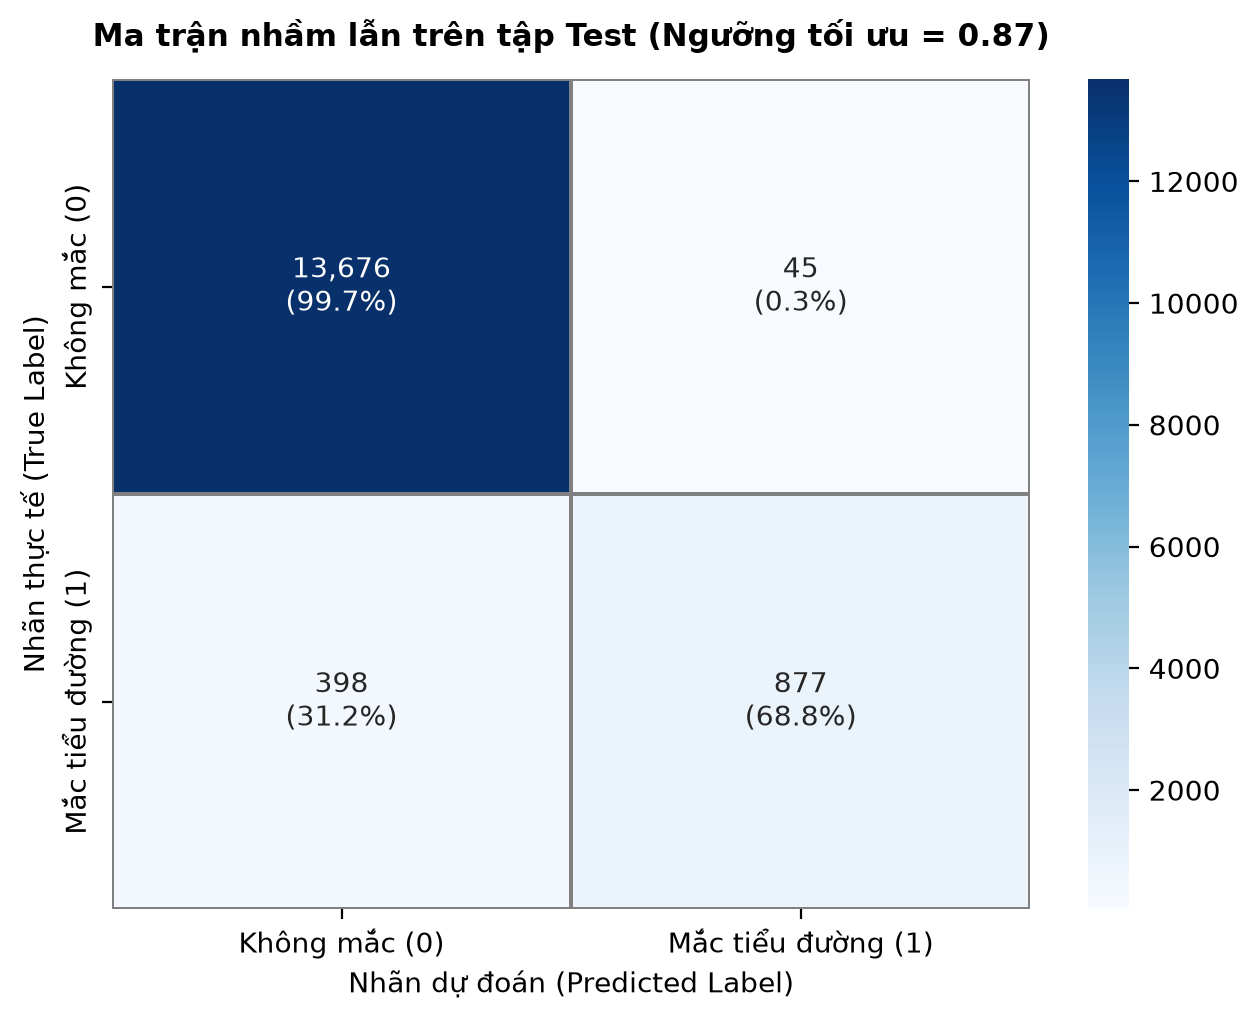

Đã lưu ma trận nhầm lẫn: outputs/figures/f_nb01_test_confusion_matrix.png


In [26]:
# Cell 5.2: Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix) trên tập Test
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# 1. Tính toán ma trận nhầm lẫn tuyệt đối và ma trận chuẩn hóa tỷ lệ (%)
cm = confusion_matrix(y_test, test_preds_opt)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

labels = [f"{val:,}\n({pct:.1f}%)" for val, pct in zip(cm.flatten(), cm_norm.flatten())]
labels = np.asarray(labels).reshape(2, 2)

# 2. Vẽ biểu đồ Heatmap chuẩn 200 dpi
plt.figure(figsize=(6.5, 5.2), dpi=200)
sns.heatmap(
    cm,
    annot=labels,
    fmt="",
    cmap="Blues",
    cbar=True,
    xticklabels=["Không mắc (0)", "Mắc tiểu đường (1)"],
    yticklabels=["Không mắc (0)", "Mắc tiểu đường (1)"],
    linewidths=0.8,
    linecolor="gray"
)

plt.title(f"Ma trận nhầm lẫn trên tập Test (Ngưỡng tối ưu = {opt_threshold:.2f})", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10)
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10)
plt.tight_layout()

# 3. Lưu hình ảnh
os.makedirs("outputs/figures", exist_ok=True)
fig_cm_path = "outputs/figures/f_nb01_test_confusion_matrix.png"
plt.savefig(fig_cm_path, dpi=200)
plt.show()
print(f"Đã lưu ma trận nhầm lẫn: {fig_cm_path}")

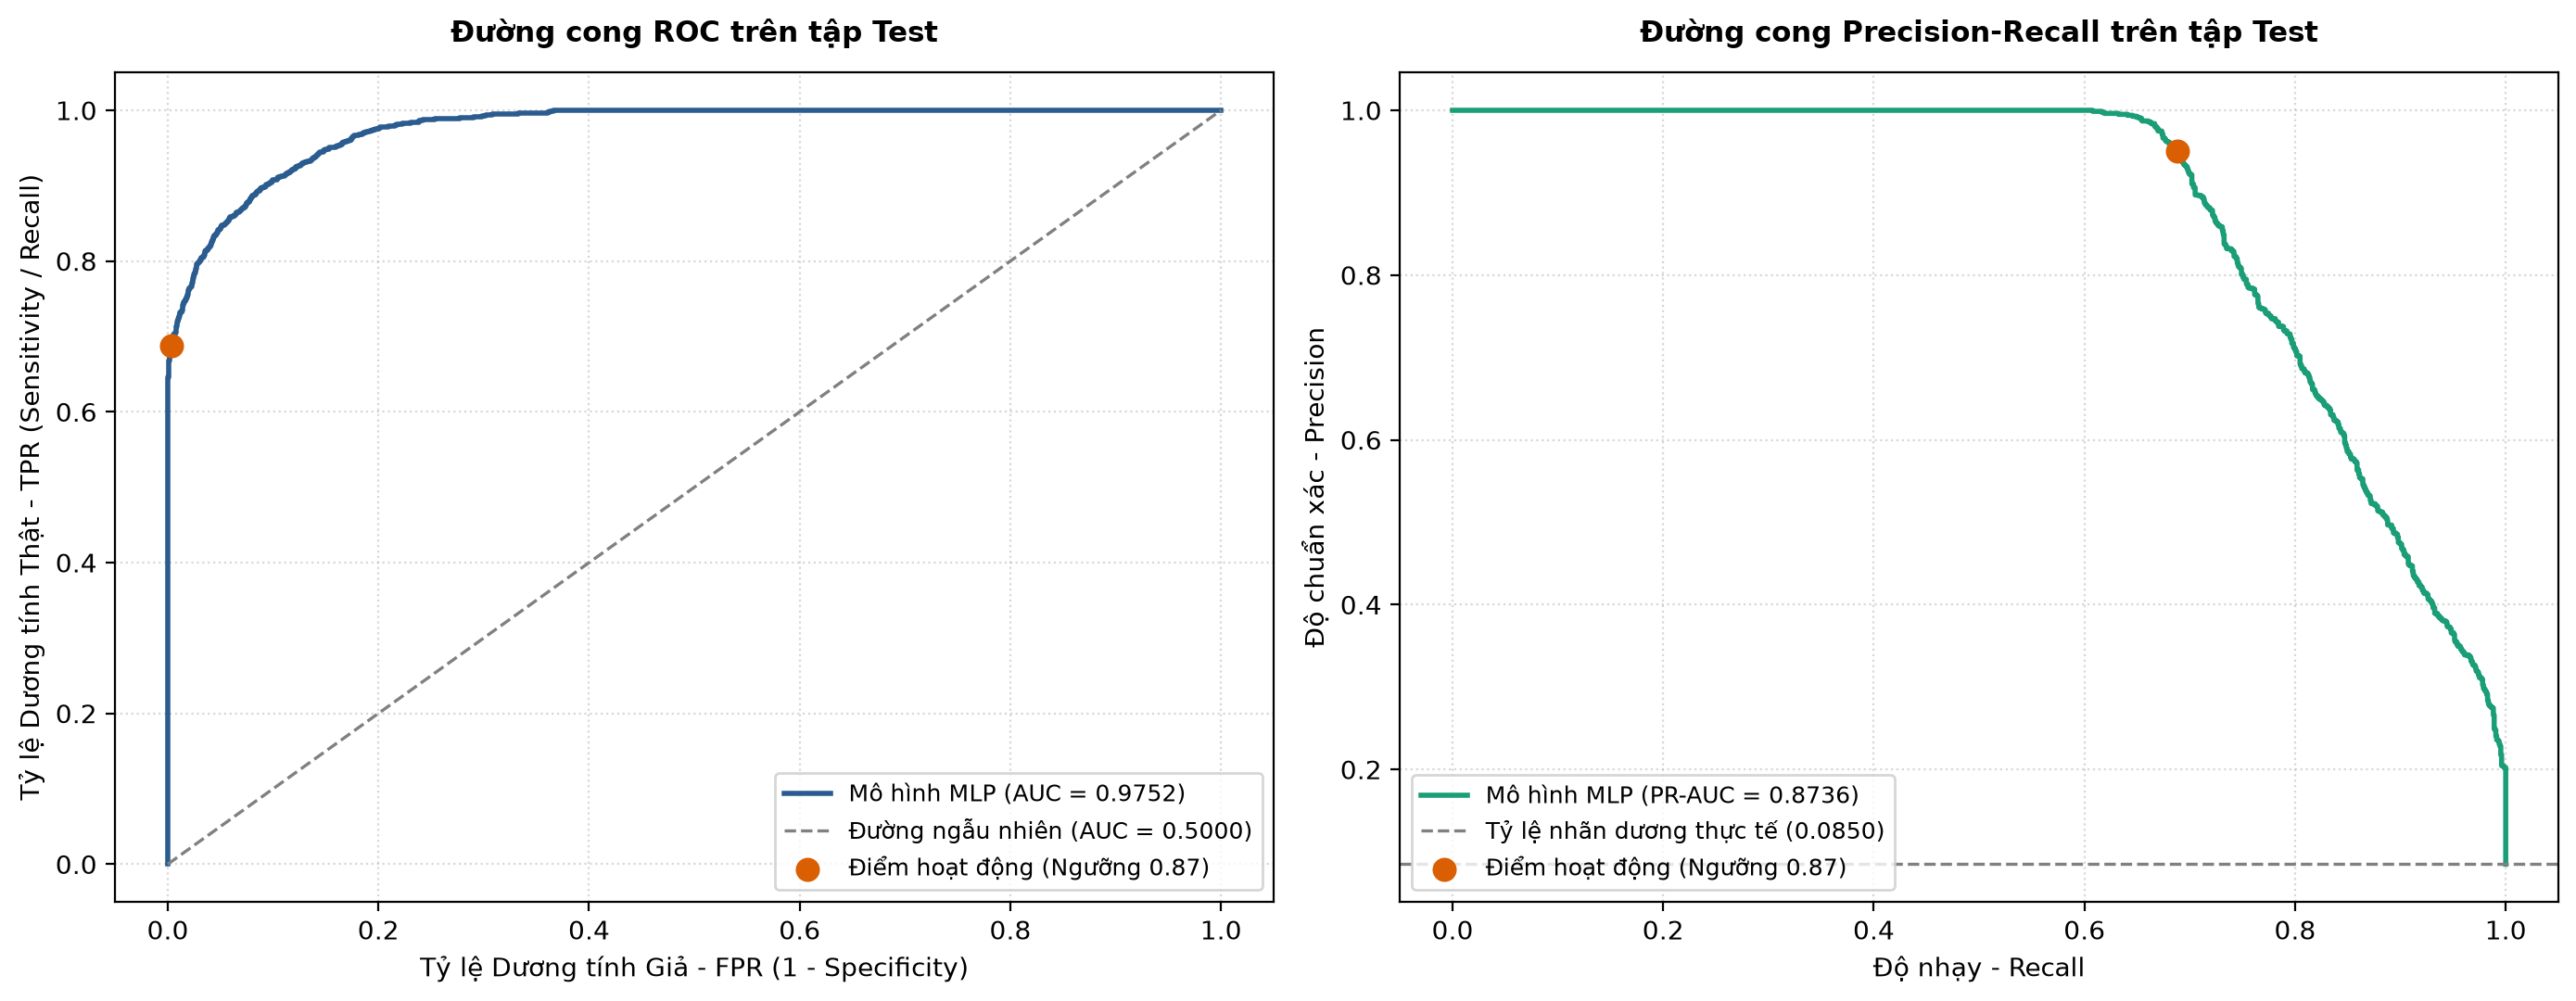

Đã lưu biểu đồ ROC và PR curves: outputs/figures/f_nb01_test_roc_pr.png


In [27]:
# Cell 5.3: Trực quan hóa Đường cong ROC và Đường cong Precision-Recall
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

fpr, tpr, roc_thresholds = roc_curve(y_test, test_probs)
precisions, recalls, pr_thresholds = precision_recall_curve(y_test, test_probs)

roc_auc_val = roc_auc_score(y_test, test_probs)
pr_auc_val = average_precision_score(y_test, test_probs)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=200)

# 1. Đường cong ROC
axes[0].plot(fpr, tpr, color="#2b5c8f", lw=2, label=f"Mô hình MLP (AUC = {roc_auc_val:.4f})")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--", lw=1.2, label="Đường ngẫu nhiên (AUC = 0.5000)")
idx_roc_opt = np.argmin(np.abs(roc_thresholds - opt_threshold))
axes[0].scatter(fpr[idx_roc_opt], tpr[idx_roc_opt], color="#d95f02", s=70, zorder=5, label=f"Điểm hoạt động (Ngưỡng {opt_threshold:.2f})")
axes[0].set_title("Đường cong ROC trên tập Test", fontsize=11, fontweight="bold", pad=12)
axes[0].set_xlabel("Tỷ lệ Dương tính Giả - FPR (1 - Specificity)", fontsize=10)
axes[0].set_ylabel("Tỷ lệ Dương tính Thật - TPR (Sensitivity / Recall)", fontsize=10)
axes[0].legend(loc="lower right", fontsize=9)
axes[0].grid(True, linestyle=":", alpha=0.5)

# 2. Đường cong Precision-Recall (Metric cốt lõi cho phân bố mất cân bằng)
axes[1].plot(recalls, precisions, color="#1b9e77", lw=2, label=f"Mô hình MLP (PR-AUC = {pr_auc_val:.4f})")
prevalence_rate = float((y_test == 1).sum() / len(y_test))
axes[1].axhline(y=prevalence_rate, color="gray", linestyle="--", lw=1.2, label=f"Tỷ lệ nhãn dương thực tế ({prevalence_rate:.4f})")
idx_pr_opt = np.argmin(np.abs(pr_thresholds - opt_threshold))
axes[1].scatter(recalls[idx_pr_opt], precisions[idx_pr_opt], color="#d95f02", s=70, zorder=5, label=f"Điểm hoạt động (Ngưỡng {opt_threshold:.2f})")
axes[1].set_title("Đường cong Precision-Recall trên tập Test", fontsize=11, fontweight="bold", pad=12)
axes[1].set_xlabel("Độ nhạy - Recall", fontsize=10)
axes[1].set_ylabel("Độ chuẩn xác - Precision", fontsize=10)
axes[1].legend(loc="lower left", fontsize=9)
axes[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
fig_roc_pr_path = "outputs/figures/f_nb01_test_roc_pr.png"
plt.savefig(fig_roc_pr_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ ROC và PR curves: {fig_roc_pr_path}")

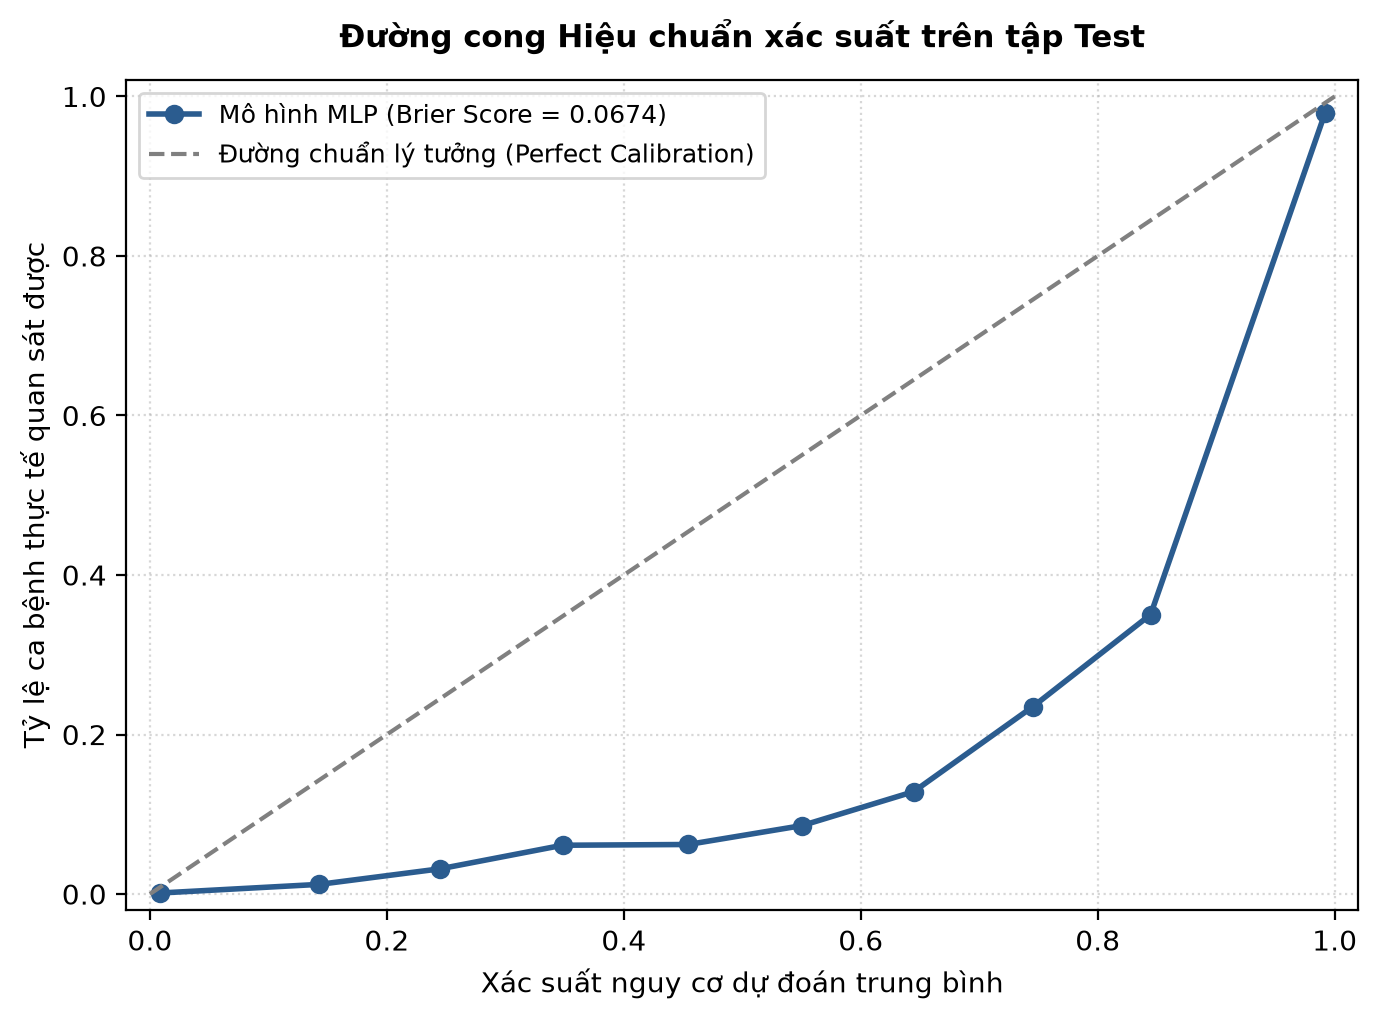

Đã lưu biểu đồ hiệu chuẩn: outputs/figures/f_nb01_calibration.png


In [28]:
# Cell 5.4: Đường cong Hiệu chuẩn xác suất (Calibration Curve) và Brier Score
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# 1. Phân chia 10 khoảng xác suất đồng đều để so sánh xác suất dự đoán và tỷ lệ bệnh thật
prob_true, prob_pred = calibration_curve(y_test, test_probs, n_bins=10, strategy="uniform")
brier_score = brier_score_loss(y_test, test_probs)

# 2. Trực quan hóa Calibration Curve
plt.figure(figsize=(7, 5.2), dpi=200)
plt.plot(prob_pred, prob_true, marker="o", lw=2, color="#2b5c8f", label=f"Mô hình MLP (Brier Score = {brier_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Đường chuẩn lý tưởng (Perfect Calibration)")

plt.title("Đường cong Hiệu chuẩn xác suất trên tập Test", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Xác suất nguy cơ dự đoán trung bình", fontsize=10)
plt.ylabel("Tỷ lệ ca bệnh thực tế quan sát được", fontsize=10)
plt.xlim(-0.02, 1.02)
plt.ylim(-0.02, 1.02)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()

fig_calib_path = "outputs/figures/f_nb01_calibration.png"
plt.savefig(fig_calib_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ hiệu chuẩn: {fig_calib_path}")

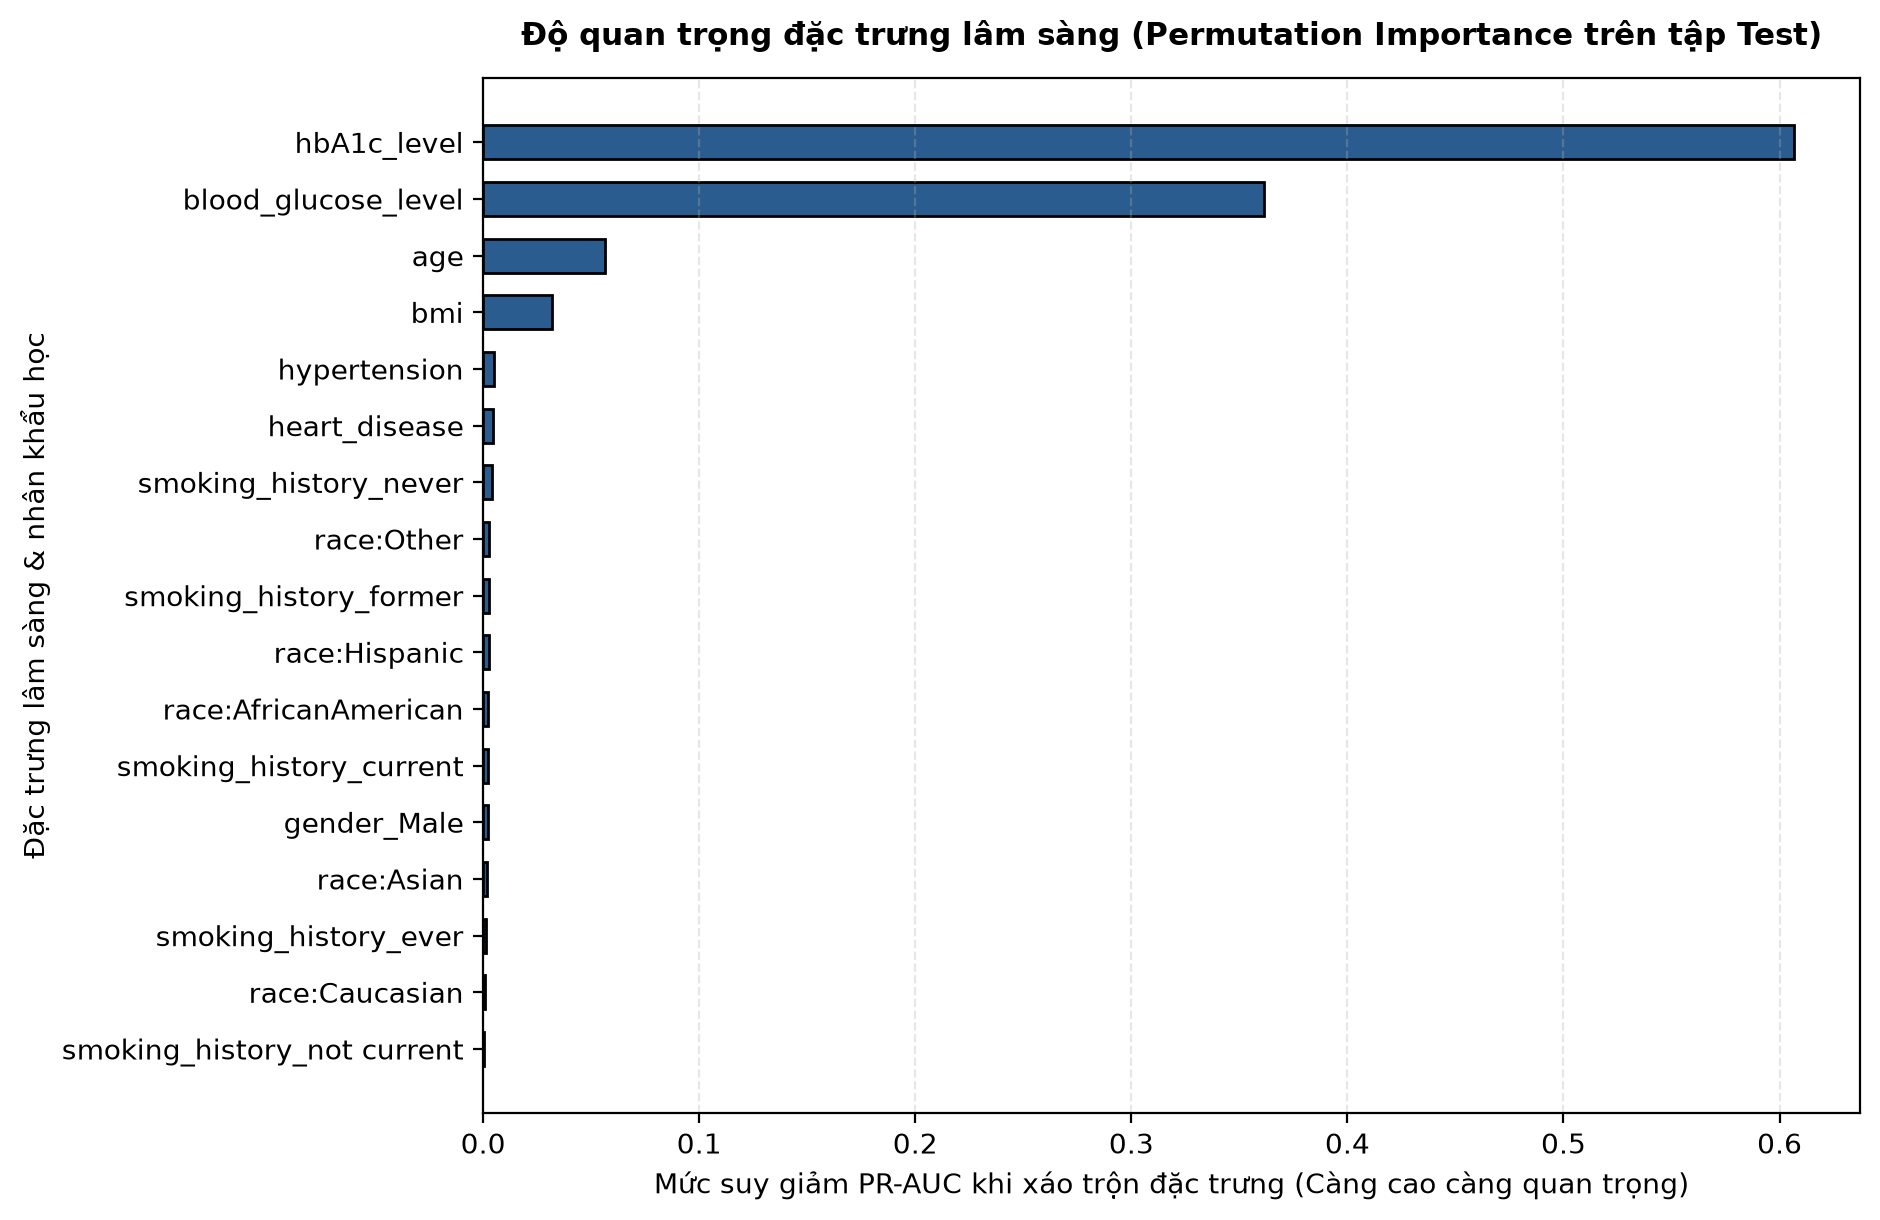

=== XẾP HẠNG ĐỘ QUAN TRỌNG ĐẶC TRƯNG LÂM SÀNG ===


,feature,importance_drop_pr_auc
0,hbA1c_level,0.606879
1,blood_glucose_level,0.361431
2,age,0.056176
3,bmi,0.031877
4,hypertension,0.005012
5,heart_disease,0.004622
6,smoking_history_never,0.003889
7,race:Other,0.002893
8,smoking_history_former,0.002753
9,race:Hispanic,0.002621


In [29]:
# Cell 5.5: Đánh giá độ quan trọng đặc trưng bằng Permutation Feature Importance
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Đo lường mức sụt giảm chỉ số PR-AUC khi xáo trộn từng đặc trưng
baseline_pr_auc = average_precision_score(y_test, test_probs)
feature_importance_records = []

np.random.seed(SEED)
for j, feat_col in enumerate(feature_names):
    X_permuted = X_test_proc.copy()
    X_permuted[:, j] = np.random.permutation(X_permuted[:, j])
    
    with torch.no_grad():
        perm_logits = mlp_model(torch.tensor(X_permuted, dtype=torch.float32).to(device))
        perm_probs = torch.sigmoid(perm_logits).cpu().numpy()
        
    perm_score = average_precision_score(y_test, perm_probs)
    drop_score = baseline_pr_auc - perm_score
    clean_name = feat_col.replace("num__", "").replace("cat__", "").replace("bin__", "")
    feature_importance_records.append({
        "feature": clean_name,
        "importance_drop_pr_auc": drop_score
    })

df_fi = pd.DataFrame(feature_importance_records).sort_values(by="importance_drop_pr_auc", ascending=True)

# 2. Vẽ biểu đồ thanh ngang độ quan trọng
plt.figure(figsize=(9.5, 6.2), dpi=200)
plt.barh(df_fi["feature"], df_fi["importance_drop_pr_auc"], color="#2b5c8f", edgecolor="black", height=0.6)
plt.title("Độ quan trọng đặc trưng lâm sàng (Permutation Importance trên tập Test)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Mức suy giảm PR-AUC khi xáo trộn đặc trưng (Càng cao càng quan trọng)", fontsize=10)
plt.ylabel("Đặc trưng lâm sàng & nhân khẩu học", fontsize=10)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

fig_fi_path = "outputs/figures/f_nb01_feature_importance.png"
plt.savefig(fig_fi_path, dpi=200)
plt.show()

print("=== XẾP HẠNG ĐỘ QUAN TRỌNG ĐẶC TRƯNG LÂM SÀNG ===")
display(df_fi.sort_values(by="importance_drop_pr_auc", ascending=False).reset_index(drop=True))

In [30]:
# Cell 5.6: Kiểm định độ ổn định mô hình qua 5 Random Seeds độc lập
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

SEEDS_LIST = [42, 101, 2024, 777, 9999]
multiseed_test_results = []

val_loader_eval = torch.utils.data.DataLoader(val_dataset, batch_size=1024, shuffle=False)
test_tensor_device = torch.tensor(X_test_proc, dtype=torch.float32).to(device)

print(f"=== TIẾN HÀNH THỰC NGHIỆM ĐA SEED ({len(SEEDS_LIST)} SEEDS) ===")
for s in SEEDS_LIST:
    set_seed(s)
    
    # 1. Khởi tạo và huấn luyện mô hình theo seed s
    seed_model = DiabetesMLP(input_dim=len(feature_names), hidden_dim1=64, hidden_dim2=32, dropout_rate=0.2).to(device)
    optimizer_s = torch.optim.AdamW(seed_model.parameters(), lr=1e-3, weight_decay=1e-4)
    criterion_s = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
    
    train_loader_s = torch.utils.data.DataLoader(train_dataset, batch_size=512, shuffle=True)
    
    best_pr_s = -1.0
    best_weights_s = None
    
    for epoch in range(1, 16):
        seed_model.train()
        for bx, by in train_loader_s:
            bx, by = bx.to(device), by.to(device)
            optimizer_s.zero_grad()
            loss = criterion_s(seed_model(bx), by)
            loss.backward()
            optimizer_s.step()
            
        seed_model.eval()
        v_probs, v_targets = [], []
        with torch.no_grad():
            for bx, by in val_loader_eval:
                probs = torch.sigmoid(seed_model(bx.to(device))).cpu().numpy()
                v_probs.extend(probs)
                v_targets.extend(by.numpy())
        val_pr_s = average_precision_score(v_targets, v_probs)
        if val_pr_s > best_pr_s:
            best_pr_s = val_pr_s
            best_weights_s = copy.deepcopy(seed_model.state_dict())
            
    # 2. Dò tìm ngưỡng tối ưu F1 trên tập Validation với mô hình seed s
    seed_model.load_state_dict(best_weights_s)
    seed_model.eval()
    with torch.no_grad():
        val_logits_s = seed_model(torch.tensor(X_val_proc, dtype=torch.float32).to(device))
        val_probs_s = torch.sigmoid(val_logits_s).cpu().numpy()
        
    th_s_opt = 0.50
    best_f1_s = 0.0
    for th in np.linspace(0.05, 0.95, 91):
        preds = (val_probs_s >= th).astype(int)
        f = f1_score(y_val, preds, zero_division=0)
        if f > best_f1_s:
            best_f1_s = f
            th_s_opt = th
            
    # 3. Đánh giá duy nhất trên tập Test
    with torch.no_grad():
        test_logits_s = seed_model(test_tensor_device)
        test_probs_s = torch.sigmoid(test_logits_s).cpu().numpy()
        
    test_preds_s = (test_probs_s >= th_s_opt).astype(int)
    
    seed_entry = {
        "seed": s,
        "threshold_optimal": round(float(th_s_opt), 2),
        "accuracy": round(float(accuracy_score(y_test, test_preds_s)), 4),
        "precision": round(float(precision_score(y_test, test_preds_s, zero_division=0)), 4),
        "recall": round(float(recall_score(y_test, test_preds_s, zero_division=0)), 4),
        "f1_score": round(float(f1_score(y_test, test_preds_s, zero_division=0)), 4),
        "roc_auc": round(float(roc_auc_score(y_test, test_probs_s)), 4),
        "pr_auc": round(float(average_precision_score(y_test, test_probs_s)), 4)
    }
    multiseed_test_results.append(seed_entry)
    print(f">> Hoàn tất Seed {s:04d} | Ngưỡng: {seed_entry['threshold_optimal']} | Test PR-AUC: {seed_entry['pr_auc']:.4f} | Test F1: {seed_entry['f1_score']:.4f}")

# 4. Tính toán giá trị Trung bình (Mean) và Độ lệch chuẩn (Std)
df_seeds = pd.DataFrame(multiseed_test_results)
metrics_cols = ["accuracy", "precision", "recall", "f1_score", "roc_auc", "pr_auc"]

aggregated_summary = []
for m in metrics_cols:
    m_mean = df_seeds[m].mean()
    m_std = df_seeds[m].std()
    aggregated_summary.append({
        "Chỉ số đánh giá": m.upper(),
        "Trung bình ± Độ lệch chuẩn (Mean ± Std)": f"{m_mean:.4f} ± {m_std:.4f}",
        "Mean": round(float(m_mean), 4),
        "Std": round(float(m_std), 4)
    })

df_multiseed_summary = pd.DataFrame(aggregated_summary)
print("\n=== BẢNG TỔNG HỢP HIỆU NĂNG TẬP TEST TRÊN 5 SEEDS (MEAN ± STD) ===")
display(df_multiseed_summary[["Chỉ số đánh giá", "Trung bình ± Độ lệch chuẩn (Mean ± Std)"]])

# 5. Lưu kết quả đa seed ra file JSON
multiseed_payload = {
    "individual_seed_runs": multiseed_test_results,
    "aggregated_summary": aggregated_summary
}
multiseed_json_path = "outputs/metrics/nb01_test_multiseed_metrics.json"
with open(multiseed_json_path, "w", encoding="utf-8") as f:
    json.dump(multiseed_payload, f, indent=4, ensure_ascii=False)
print(f"Đã lưu kết quả đa seed vào: {multiseed_json_path}")

=== TIẾN HÀNH THỰC NGHIỆM ĐA SEED (5 SEEDS) ===
>> Hoàn tất Seed 0042 | Ngưỡng: 0.86 | Test PR-AUC: 0.8678 | Test F1: 0.7862
>> Hoàn tất Seed 0101 | Ngưỡng: 0.82 | Test PR-AUC: 0.8686 | Test F1: 0.7841
>> Hoàn tất Seed 2024 | Ngưỡng: 0.87 | Test PR-AUC: 0.8687 | Test F1: 0.7914
>> Hoàn tất Seed 0777 | Ngưỡng: 0.84 | Test PR-AUC: 0.8697 | Test F1: 0.7850
>> Hoàn tất Seed 9999 | Ngưỡng: 0.86 | Test PR-AUC: 0.8693 | Test F1: 0.7885

=== BẢNG TỔNG HỢP HIỆU NĂNG TẬP TEST TRÊN 5 SEEDS (MEAN ± STD) ===


,Chỉ số đánh giá,Trung bình ± Độ lệch chuẩn (Mean ± Std)
0,ACCURACY,0.9682 ± 0.0008
1,PRECISION,0.9137 ± 0.0194
2,RECALL,0.6915 ± 0.0094
3,F1_SCORE,0.7870 ± 0.0029
4,ROC_AUC,0.9745 ± 0.0003
5,PR_AUC,0.8688 ± 0.0007


Đã lưu kết quả đa seed vào: outputs/metrics/nb01_test_multiseed_metrics.json


In [31]:
# Cell 6.1: Khởi tạo môi trường ONNX và nạp checkpoint PyTorch tối ưu
import os
import sys
import subprocess
import torch
import torch.nn as nn

# 1. Tự động cài đặt onnx và onnxruntime nếu môi trường chưa tích hợp
for pkg in ["onnx", "onnxruntime"]:
    try:
        __import__(pkg)
    except ImportError:
        print(f"Đang cài đặt thư viện {pkg}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import onnx
import onnxruntime as ort

print(f"ONNX version       : {onnx.__version__}")
print(f"ONNX Runtime version: {ort.__version__}")

# 2. Khởi tạo kiến trúc và tái nạp trọng số tốt nhất
pt_model = DiabetesMLP(input_dim=len(feature_names), hidden_dim1=64, hidden_dim2=32, dropout_rate=0.2)
best_model_path = "outputs/models/best_mlp_model.pt"
if not os.path.exists(best_model_path):
    raise FileNotFoundError(f"Không tìm thấy file {best_model_path}. Hãy chạy xong Chặng 4 trước!")

pt_model.load_state_dict(torch.load(best_model_path, map_location="cpu"))
pt_model.eval()
print(f"Trạng thái: Đã nạp thành công checkpoint từ {best_model_path} vào CPU ở chế độ eval().")

Đang cài đặt thư viện onnx...
Đang cài đặt thư viện onnxruntime...
ONNX version       : 1.23.2
ONNX Runtime version: 1.31.1
Trạng thái: Đã nạp thành công checkpoint từ outputs/models/best_mlp_model.pt vào CPU ở chế độ eval().


In [34]:
# Cell 6.2: Xuất mô hình PyTorch sang định dạng chuẩn ONNX (Đã sửa lỗi onnxscript)
import inspect
import subprocess
import sys
import torch
import torch.nn as nn
import onnx

class ONNXRiskInferenceWrapper(nn.Module):
    """Lớp bao bọc xuất trực tiếp xác suất nguy cơ sigmoid(logits) cho Agent NB02/NB03."""
    def __init__(self, base_mlp: nn.Module):
        super().__init__()
        self.base_mlp = base_mlp

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        logits = self.base_mlp(x)
        probabilities = torch.sigmoid(logits)
        return probabilities

# 1. Khởi tạo wrapper suy luận
inference_model = ONNXRiskInferenceWrapper(pt_model)
inference_model.eval()

# 2. Tạo tensor đầu vào giả định (dummy input) 17 chiều
dummy_input = torch.randn(1, len(feature_names), dtype=torch.float32)
onnx_output_path = "outputs/models/risk_model.onnx"

# 3. Cấu hình tham số export
export_kwargs = {
    "export_params": True,
    "opset_version": 14,
    "do_constant_folding": True,
    "input_names": ["clinical_features"],
    "output_names": ["diabetes_risk_probability"],
    "dynamic_axes": {
        "clinical_features": {0: "batch_size"},
        "diabetes_risk_probability": {0: "batch_size"}
    }
}

# Nếu PyTorch hiện tại có tham số dynamo, ép dynamo=False để dùng legacy TorchScript exporter
if "dynamo" in inspect.signature(torch.onnx.export).parameters:
    export_kwargs["dynamo"] = False

# 4. Thực thi xuất mô hình ONNX kèm cơ chế tự động cài onnxscript nếu hệ thống vẫn yêu cầu
try:
    torch.onnx.export(
        inference_model,
        dummy_input,
        onnx_output_path,
        **export_kwargs
    )
except ModuleNotFoundError as e:
    if "onnxscript" in str(e):
        print("Đang bổ sung thư viện onnxscript...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "onnxscript"])
        torch.onnx.export(
            inference_model,
            dummy_input,
            onnx_output_path,
            **export_kwargs
        )
    else:
        raise e

# 5. Kiểm định cấu trúc đồ thị tính toán ONNX
onnx_proto = onnx.load(onnx_output_path)
onnx.checker.check_model(onnx_proto)

print(f"=== XUẤT ONNX THÀNH CÔNG ===")
print(f"- Tệp lưu trữ   : {onnx_output_path}")
print(f"- Kích thước tệp: {os.path.getsize(onnx_output_path) / 1024:.2f} KB")
print(f"- Tên tensor vào: {onnx_proto.graph.input[0].name}")
print(f"- Tên tensor ra : {onnx_proto.graph.output[0].name}")

=== XUẤT ONNX THÀNH CÔNG ===
- Tệp lưu trữ   : outputs/models/risk_model.onnx
- Kích thước tệp: 16.73 KB
- Tên tensor vào: clinical_features
- Tên tensor ra : diabetes_risk_probability


C:\Users\Huy\AppData\Local\Temp\ipykernel_13688\890372037.py:47: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


In [35]:
# Cell 6.3: Kiểm tra đối chiếu độ chính xác suy luận giữa PyTorch và ONNX Runtime
import numpy as np

# 1. Khởi tạo phiên suy luận ONNX Runtime
ort_session = ort.InferenceSession(onnx_output_path, providers=["CPUExecutionProvider"])
input_name = ort_session.get_inputs()[0].name
output_name = ort_session.get_outputs()[0].name

# 2. Chạy suy luận với PyTorch trên tập Test
with torch.no_grad():
    torch_input_test = torch.tensor(X_test_proc, dtype=torch.float32)
    torch_probs = inference_model(torch_input_test).cpu().numpy()

# 3. Chạy suy luận với ONNX Runtime trên cùng tập Test
ort_inputs = {input_name: X_test_proc.astype(np.float32)}
ort_probs = ort_session.run([output_name], ort_inputs)[0]

# 4. Tính toán mức sai số số học (Numerical Discrepancy)
abs_diff = np.abs(torch_probs - ort_probs)
max_abs_diff = float(np.max(abs_diff))
mean_abs_diff = float(np.mean(abs_diff))

print("=== KIỂM ĐỊNH TÍNH NHẤT QUÁN SUY LUẬN (PYTORCH VS ONNX) ===")
print(f"Số lượng mẫu kiểm định          : {len(X_test_proc):,} bệnh nhân")
print(f"Sai số tuyệt đối trung bình     : {mean_abs_diff:.8e}")
print(f"Sai số tuyệt đối cực đại (Max)  : {max_abs_diff:.8e}")

TOLERANCE = 1e-5
if max_abs_diff < TOLERANCE:
    print(f" KẾT QUẢ ĐẠT: Đầu ra ONNX hoàn toàn đồng nhất với PyTorch (Sai số < {TOLERANCE}).")
else:
    print(f" CẢNH BÁO: Sai số vượt ngưỡng {TOLERANCE}, cần kiểm tra lại các phép toán chuyển đổi.")

=== KIỂM ĐỊNH TÍNH NHẤT QUÁN SUY LUẬN (PYTORCH VS ONNX) ===
Số lượng mẫu kiểm định          : 14,996 bệnh nhân
Sai số tuyệt đối trung bình     : 1.75649575e-08
Sai số tuyệt đối cực đại (Max)  : 1.78813934e-07
 KẾT QUẢ ĐẠT: Đầu ra ONNX hoàn toàn đồng nhất với PyTorch (Sai số < 1e-05).


In [36]:
# Cell 6.4: Xuất scaler.json và feature_schema.json phục vụ tích hợp Agent
import json

# 1. Trích xuất tham số kỹ thuật tiền xử lý từ preprocessor (fitted trên Train)
num_scaler = preprocessor.named_transformers_["num"]
cat_encoder = preprocessor.named_transformers_["cat"]

scaler_specs = {
    "framework": "scikit-learn ColumnTransformer",
    "feature_dimensions_input": len(clinical_num_features) + len(clinical_cat_features) + len(binary_clinical_features),
    "feature_dimensions_transformed": len(feature_names),
    "numerical_features": clinical_num_features,
    "scaler_mean": [round(float(x), 6) for x in num_scaler.mean_],
    "scaler_scale": [round(float(x), 6) for x in num_scaler.scale_],
    "scaler_var": [round(float(x), 6) for x in num_scaler.var_],
    "categorical_features": clinical_cat_features,
    "categories_mapping": {
        col: cats.tolist() for col, cats in zip(clinical_cat_features, cat_encoder.categories_)
    },
    "binary_features": binary_clinical_features,
    "transformed_feature_names": feature_names
}

scaler_json_path = "outputs/models/scaler.json"
with open(scaler_json_path, "w", encoding="utf-8") as f:
    json.dump(scaler_specs, f, indent=4, ensure_ascii=False)
print(f"Đã lưu thông số tiền xử lý: {scaler_json_path}")

# 2. Xây dựng lược đồ đặc trưng lâm sàng (Feature Schema & Safety Guardrails)
feature_schema = {
    "project": "Hệ đa agent tư vấn bệnh nhân tiểu đường - NB01 Classification Contract",
    "model_target": "diabetes (0: Nguy cơ thấp/Không mắc, 1: Nguy cơ cao/Mắc bệnh)",
    "decision_threshold_f1_optimal": opt_threshold,
    "input_features_schema": [
        {
            "name": "age",
            "type": "float",
            "unit": "tuổi (năm)",
            "valid_range": {"min": 0.08, "max": 120.0},
            "description": "Tuổi của bệnh nhân tại thời điểm khảo sát"
        },
        {
            "name": "bmi",
            "type": "float",
            "unit": "kg/m²",
            "valid_range": {"min": 10.0, "max": 100.0},
            "description": "Chỉ số khối cơ thể (Body Mass Index)"
        },
        {
            "name": "hbA1c_level",
            "type": "float",
            "unit": "%",
            "valid_range": {"min": 3.0, "max": 18.0},
            "description": "Chỉ số đường huyết gắn Hemoglobin A1c (ngưỡng ADA >= 6.5% là đái tháo đường)"
        },
        {
            "name": "blood_glucose_level",
            "type": "float",
            "unit": "mg/dL",
            "valid_range": {"min": 40.0, "max": 600.0},
            "description": "Nồng độ glucose huyết ngẫu nhiên/lúc đói"
        },
        {
            "name": "gender",
            "type": "string",
            "valid_values": ["Female", "Male"],
            "description": "Giới tính sinh học của bệnh nhân"
        },
        {
            "name": "smoking_history",
            "type": "string",
            "valid_values": ["No Info", "never", "former", "current", "not current", "ever"],
            "description": "Tiền sử và thói quen hút thuốc lá"
        },
        {
            "name": "hypertension",
            "type": "int",
            "valid_values": [0, 1],
            "description": "Tiền sử chẩn đoán bệnh tăng huyết áp (0: Không, 1: Có)"
        },
        {
            "name": "heart_disease",
            "type": "int",
            "valid_values": [0, 1],
            "description": "Tiền sử bệnh lý tim mạch (0: Không, 1: Có)"
        },
        {
            "name": "race:AfricanAmerican", "type": "int", "valid_values": [0, 1], "description": "Chủng tộc người Mỹ gốc Phi"
        },
        {
            "name": "race:Asian", "type": "int", "valid_values": [0, 1], "description": "Chủng tộc người gốc Á"
        },
        {
            "name": "race:Caucasian", "type": "int", "valid_values": [0, 1], "description": "Chủng tộc người da trắng"
        },
        {
            "name": "race:Hispanic", "type": "int", "valid_values": [0, 1], "description": "Chủng tộc người gốc Tây Ban Nha/Mỹ Latinh"
        },
        {
            "name": "race:Other", "type": "int", "valid_values": [0, 1], "description": "Chủng tộc khác"
        }
    ],
    "academic_disclaimer": "Mô hình chỉ phục vụ dự báo rủi ro thống kê trong khuôn khổ đồ án học thuật, không có giá trị chẩn đoán lâm sàng độc lập."
}

schema_json_path = "outputs/models/feature_schema.json"
with open(schema_json_path, "w", encoding="utf-8") as f:
    json.dump(feature_schema, f, indent=4, ensure_ascii=False)
print(f"Đã lưu lược đồ giao tiếp Agent: {schema_json_path}")

Đã lưu thông số tiền xử lý: outputs/models/scaler.json
Đã lưu lược đồ giao tiếp Agent: outputs/models/feature_schema.json


In [37]:
# Cell 6.5: Tổng hợp toàn diện kết quả thực nghiệm vào outputs/metrics/dl_metrics.json
import json
import os

# 1. Đọc các tệp metrics đã lưu từ các chặng trước
def load_json_safe(filepath: str):
    if os.path.exists(filepath):
        with open(filepath, "r", encoding="utf-8") as f:
            return json.load(f)
    return {}

protocol_data = load_json_safe("outputs/metrics/evaluation_protocol.json")
baseline_data = load_json_safe("outputs/metrics/nb01_baseline_val_metrics.json")
mlp_val_data = load_json_safe("outputs/metrics/nb01_mlp_val_metrics.json")
test_eval_data = load_json_safe("outputs/metrics/nb01_test_evaluation.json")
multiseed_data = load_json_safe("outputs/metrics/nb01_test_multiseed_metrics.json")

# 2. Hợp nhất thành payload báo cáo kỹ thuật hoàn chỉnh
consolidated_dl_metrics = {
    "project_title": "Hệ đa agent hỗ trợ tư vấn cho bệnh nhân tiểu đường - NB01 Deep Learning Report",
    "dataset_summary": {
        "dataset_name": "diabetes_dataset.csv",
        "total_records_after_cleaning": len(X),
        "input_features_count": len(feature_names),
        "split_ratios": {"train": 0.70, "val": 0.15, "test": 0.15},
        "positive_class_ratio_percent": 8.50
    },
    "evaluation_protocol": protocol_data,
    "baseline_validation_benchmarks": baseline_data,
    "deep_learning_mlp_validation": mlp_val_data,
    "test_set_definitive_evaluation": test_eval_data,
    "multi_seed_robustness": multiseed_data,
    "exported_artifacts": {
        "onnx_model": "outputs/models/risk_model.onnx",
        "scaler_json": "outputs/models/scaler.json",
        "feature_schema": "outputs/models/feature_schema.json"
    }
}

final_metrics_path = "outputs/metrics/dl_metrics.json"
with open(final_metrics_path, "w", encoding="utf-8") as f:
    json.dump(consolidated_dl_metrics, f, indent=4, ensure_ascii=False)

print(f"=== ĐÃ TỔNG HỢP VÀ LƯU TOÀN BỘ CHỈ SỐ THỰC NGHIỆM VÀO {final_metrics_path} ===")
print("Các phần cấu thành báo cáo:")
for key in consolidated_dl_metrics.keys():
    print(f"- {key}")

=== ĐÃ TỔNG HỢP VÀ LƯU TOÀN BỘ CHỈ SỐ THỰC NGHIỆM VÀO outputs/metrics/dl_metrics.json ===
Các phần cấu thành báo cáo:
- project_title
- dataset_summary
- evaluation_protocol
- baseline_validation_benchmarks
- deep_learning_mlp_validation
- test_set_definitive_evaluation
- multi_seed_robustness
- exported_artifacts


In [38]:
# Cell 6.6: Trích xuất và lưu trữ danh mục thư viện pip freeze
import subprocess
import sys
import os

os.makedirs("outputs", exist_ok=True)
freeze_output_path = "outputs/pip_freeze.txt"

# Thực thi lệnh pip freeze bằng tiến trình nội bộ
try:
    freeze_bytes = subprocess.check_output([sys.executable, "-m", "pip", "freeze"])
    freeze_str = freeze_bytes.decode("utf-8")
    
    with open(freeze_output_path, "w", encoding="utf-8") as f:
        f.write(freeze_str)
        
    line_count = len(freeze_str.strip().split("\n"))
    print(f"=== ĐÓNG GÓI MÔI TRƯỜNG THÀNH CÔNG ===")
    print(f"- Tệp ghi nhận     : {freeze_output_path}")
    print(f"- Tổng số thư viện : {line_count} packages")
    print(f"\n10 dòng đầu tiên của {freeze_output_path}:")
    for line in freeze_str.strip().split("\n")[:10]:
        print(f"  {line}")
except Exception as e:
    print(f"Lỗi khi trích xuất pip freeze: {e}")

=== ĐÓNG GÓI MÔI TRƯỜNG THÀNH CÔNG ===
- Tệp ghi nhận     : outputs/pip_freeze.txt
- Tổng số thư viện : 401 packages

10 dòng đầu tiên của outputs/pip_freeze.txt:
  absl-py==2.5.0
  aiobotocore @ file:///C:/Users/task_178160237051488/croot/aiobotocore_1781603012329/work
  aiodns @ file:///C:/Users/task_177209691568561/croot/aiodns_1772096986334/work
  aiohappyeyeballs @ file:///C:/Users/task_178064714217164/croot/aiohappyeyeballs_1780647335941/work
  aiohttp @ file:///C:/Users/task_178645509445851/croot/aiohttp_1786455658679/work
  aioitertools @ file:///C:/b/abs_70vydn6fmg/croot/aioitertools_1754313763510/work
  aiosignal @ file:///C:/b/abs_84ej696pud/croot/aiosignal_1755870823775/work
  alabaster @ file:///C:/miniconda3/conda-bld/alabaster_1764709288682/work
  altair @ file:///C:/Users/task_178691227664711/croot/altair_1786912423697/work
  anaconda-anon-usage @ file:///home/task_178056140078668/croot/anaconda-anon-usage_1780561464840/work
